# **Marketing Customer Analysis and Propensity Modeling: Clustering of Churn Risk Using the K-Means Method to Identify Critical Offer Variables and Segment Customers**

This project aims to **analyze the churn phenomenon among customers of a Telco service company**, with the goal of **identifying the main factors of churn** and **segmenting the customer base** to support targeted retention strategies. As shown by a first exploratory data analysis, the **ratio between customers who churn and those who remain active is about 1 to 3**: for each customer who leaves the company's services (26.5%), there are about three customers who continue using them (73.5%).

An analysis is therefore carried out in **two complementary phases** to identify the Churn Profile and plan corrective actions:

### Part 1: Risky Customer Profile - Analysis of Service Purchase Variables contributing to Churn=1 statistics, in support of Offer Reinforcement strategies:

| Category | Key Insights |
|----------|--------------|
| **Contract type** | Almost all customers with a **month-to-month contract** leave the service, compared to those with an **annual** or **biennial contract**. |
| **Services not purchased** | Customers who **do not use Online Security, Online Backup, or Device Protection**, and those who **have never requested technical service interventions**, tend to leave. Digital protection services carry a **greater weight in retention** compared to entertainment services (**Streaming TV, Streaming Movies**). |
| **Technical service** | The use of **technical service intervention** appears to be a **key moment to strengthen the relationship** between the customer and the company. |
| **Services purchased** | **85%** of those using **Fiber Optic Internet Service** (compared to DSL) tend to leave, showing **sensitivity towards higher-performing Internet** and **lower loyalty to the brand with basic offers**. |
| **Payment method** | About **2 out of 3 customers** with **simple payment** (not automatic via bank transfer or credit card) leave, highlighting that a **weaker relationship with the company through the payment system** favors churn. |

### Part 2: Segmentation of Increasing-Risk Customer ID Clusters with K-Means for Targeted Retention Actions:

| Cluster | Percentage of customers | Churn risk | Description |
|---------|--------------------------|------------|-------------|
| **Cluster 0** | 45.2% | 8% | Low churn risk, stable customer base |
| **Cluster 1** | 32.8% | 44% | Intermediate risk, highest-risk segment |
| **Cluster 2** | 22.0% | 15% | Low risk, mostly stable customers but slightly more vulnerable than Cluster 0 |

This type of analysis makes it possible to build a **base customer dataset to identify the highest-risk clusters and prioritize retention interventions**, planning **marketing strategies** and **offer improvements**.  

The **combined approach** of identifying churn factors and clustering enables the transformation of customer data into **operational insights** to reduce churn and improve retention.


### Dataset: "Telco Customer Churn"
*Source: IBM Sample Data Sets*

---

### Objective
Predict **Churn** behavior (service cancellation) in order to design actions aimed at retaining customers, such as targeted loyalty programs.

---

### Dataset Content (by column)

| Category | Description |
|---|---|
| **Customer ID** | Each row represents a customer |
| **Target: Churn Status** | Customers who left the service in the last month (`Churn`) |
| **Subscribed Services** | Phone, multiple lines, internet, online security, online backup, device protection, technical support, TV and movie streaming |
| **Account Details** | Contract duration, contract type, payment method, paperless billing, monthly charges, total charges |
| **Demographic Data** | Gender, age group, presence of partner and dependents |

---


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.0/247.0 kB 14.0 MB/s eta 0:00:00


In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*Tight layout not applied.*")
warnings.filterwarnings("ignore", category=UserWarning, message=".*use_label_encoder.*")

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import MinMaxScaler

# Models
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score,confusion_matrix
from sklearn.decomposition import PCA
import optuna

# Hypothesis testing
from scipy.stats import f_oneway, chi2_contingency


In [ ]:
# Load the table
df = pd.read_csv('https://raw.githubusercontent.com/Valeria-Raele/customer-segmentation-churn-risk/refs/heads/main/datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv')


In [ ]:
df.head(20)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

### Exploratory Data Analysis (EDA) and Pre-processing

In [ ]:
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.shape

(7043, 21)

In [ ]:
for col in df.columns:
    print(f"{col} ({df[col].dtype}): {df[col].nunique()}")

customerID (object): 7043
gender (object): 2
SeniorCitizen (int64): 2
Partner (object): 2
Dependents (object): 2
tenure (int64): 73
PhoneService (object): 2
MultipleLines (object): 3
InternetService (object): 3
OnlineSecurity (object): 3
OnlineBackup (object): 3
DeviceProtection (object): 3
TechSupport (object): 3
StreamingTV (object): 3
StreamingMovies (object): 3
Contract (object): 3
PaperlessBilling (object): 2
PaymentMethod (object): 4
MonthlyCharges (float64): 1585
TotalCharges (object): 6531
Churn (object): 2


In [ ]:
cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'PaperlessBilling', 'Churn', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
    'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'
]

for col in cols:
    print(f"{col}: {df[col].unique()}")

gender: ['Female' 'Male']
SeniorCitizen: [0 1]
Partner: ['Yes' 'No']
Dependents: ['No' 'Yes']
PhoneService: ['No' 'Yes']
PaperlessBilling: ['Yes' 'No']
Churn: ['No' 'Yes']
MultipleLines: ['No phone service' 'No' 'Yes']
InternetService: ['DSL' 'Fiber optic' 'No']
OnlineSecurity: ['No' 'Yes' 'No internet service']
OnlineBackup: ['Yes' 'No' 'No internet service']
DeviceProtection: ['No' 'Yes' 'No internet service']
TechSupport: ['No' 'Yes' 'No internet service']
StreamingTV: ['No' 'Yes' 'No internet service']
StreamingMovies: ['No' 'Yes' 'No internet service']
Contract: ['Month-to-month' 'One year' 'Two year']
PaymentMethod: ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


### Target Composition

In [ ]:
# Value counts
churn_counts = df['Churn'].value_counts()

# Percentages
churn_percent = df['Churn'].value_counts(normalize=True) * 100

# Combine into a single DataFrame
churn_summary = pd.DataFrame({
    'Count': churn_counts,
    'Percentage': churn_percent
})

print(churn_summary)


       Count  Percentage
Churn                   
No      5174   73.463013
Yes     1869   26.536987


The target variable is unbalanced, with Yes - No values in a 1 to 3 ratio.
That is, out of 4 customers, for each customer who churns (26.5%), 3 customers do not churn (73.5%).

### OrdinalEncoder and OneHotEncoder for categorical variables

Let’s examine the column values:

### 1. **CustomerID**
- Contains all unique values corresponding to the dataset size and indexes the dataset → no transformation needed

---

### 2. **Binary variables** → numerical transformation 0/1
- `gender`: `Male` - `Female`
- `SeniorCitizen`: `0` - `1` (ok)
- `Partner`: `No` - `Yes`
- `Dependents`: `No` - `Yes`
- `PhoneService`: `No` - `Yes`
- `PaperlessBilling`: `No` - `Yes`
- `Churn` *(target)*: `No` - `Yes`

---

### 3. **Three / four options** → transformation with *One Hot Encoding*
- `MultipleLines`: `No` - `No phone service` - `Yes`
- `InternetService`: `No` - `DSL` - `Fiber optic`
- `OnlineSecurity`: `No` - `No internet service` - `Yes`
- `OnlineBackup`: `No` - `No internet service` - `Yes`
- `DeviceProtection`: `No` - `No internet service` - `Yes`
- `TechSupport`: `No` - `No internet service` - `Yes`
- `StreamingTV`: `No` - `No internet service` - `Yes`
- `StreamingMovies`: `No` - `No internet service` - `Yes`
- `Contract`: `Month-to-month` - `One year` - `Two year`
- `PaymentMethod` *(4 options)*:  
  - `Electronic check`  
  - `Mailed check`  
  - `Bank transfer (automatic)`  
  - `Credit card (automatic)`

---

### 4. **Numeric variables**
- `MonthlyCharges` *(1585)* → `float` → **no action needed**
- `TotalCharges` *(6531)* → `object` → **transform to `float`**


In [ ]:
# 1. Binary variables: mapping 0/1
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
df['SeniorCitizen'] = df['SeniorCitizen'].astype(int)

binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_cols:
    df[col] = df[col].map({'No': 0, 'Yes': 1})

# 2. One Hot Encoding
multi_option_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod'
]

df = pd.get_dummies(df, columns=multi_option_cols, drop_first=False)

# Force dummy columns to int (0/1): False = 0 (value not present) and True =1 (value present)
for col in df.columns:
    if df[col].dtype == 'bool':
        df[col] = df[col].astype(int)

# 3. Numeric columns
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Verify result
print(df.head())


   customerID  gender  SeniorCitizen  Partner  Dependents  tenure  \
0  7590-VHVEG       0              0        1           0       1   
1  5575-GNVDE       1              0        0           0      34   
2  3668-QPYBK       1              0        0           0       2   
3  7795-CFOCW       1              0        0           0      45   
4  9237-HQITU       0              0        0           0       2   

   PhoneService  PaperlessBilling  MonthlyCharges  TotalCharges  ...  \
0             0                 1           29.85         29.85  ...   
1             1                 0           56.95       1889.50  ...   
2             1                 1           53.85        108.15  ...   
3             0                 0           42.30       1840.75  ...   
4             1                 1           70.70        151.65  ...   

   StreamingMovies_No  StreamingMovies_No internet service  \
0                   1                                    0   
1                   1       

In [ ]:
# New list of DataFrame columns
df.columns


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges',
       'TotalCharges', 'Churn', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
      

### Dictionary of demographic, behavioral, and purchase variables in the final DataFrame

### Identifier variable
| Variable name | Description |
|---|---|
| **customerID** | Unique user ID for each customer indexing the DataFrame |

### Discrete continuous variables
| Variable name | Description |
|---|---|
| **Tenure** | Duration of the customer relationship |
| **MonthlyCharges** | Customer’s monthly charges |
| **TotalCharges** | Total charges since the beginning of the relationship |

### Binary variables
| Variable name | Description | Values |
|---|---|---|
| **gender** | Gender | 0 = female, 1 = male |
| **SeniorCitizen** | Senior age group | 0 = no, 1 = yes |
| **Partner** | Presence of partner | 0 = no, 1 = yes |
| **Dependents** | Dependents | 0 = no, 1 = yes |
| **PhoneService** | Phone service | 0 = no, 1 = yes |
| **PaperlessBilling** | Digital billing | 0 = no, 1 = yes |

### Dummy variables derived from 3 or 4-option variables
| Variable name | Description | Values |
|---|---|---|
| **MultipleLines_No** | No MultipleLines service | 0 = no, 1 = yes |
| **MultipleLines_No phone service** | MultipleLines except Phone Service | 0 = no, 1 = yes |
| **MultipleLines_Yes** | With MultipleLines service | 0 = no, 1 = yes |
| **InternetService_DSL** | DSL Internet service | 0 = no, 1 = yes |
| **InternetService_Fiber optic** | Fiber optic Internet service | 0 = no, 1 = yes |
| **InternetService_No** | No Internet service | 0 = no, 1 = yes |
| **OnlineSecurity_No** | No Internet Security service | 0 = no, 1 = yes |
| **OnlineSecurity_No internet service** | No Internet Security due to no internet | 0 = no, 1 = yes |
| **OnlineSecurity_Yes** | With Internet Security | 0 = no, 1 = yes |
| **OnlineBackup_No** | No Online Backup service | 0 = no, 1 = yes |
| **OnlineBackup_No internet service** | No Online Backup due to no internet | 0 = no, 1 = yes |
| **OnlineBackup_Yes** | With Online Backup service | 0 = no, 1 = yes |
| **DeviceProtection_No** | No Device Protection | 0 = no, 1 = yes |
| **DeviceProtection_No internet service** | No Device Protection due to no internet | 0 = no, 1 = yes |
| **DeviceProtection_Yes** | With Device Protection | 0 = no, 1 = yes |
| **TechSupport_No** | No Tech Support | 0 = no, 1 = yes |
| **TechSupport_No internet service** | No Tech Support due to no internet | 0 = no, 1 = yes |
| **TechSupport_Yes** | With Tech Support | 0 = no, 1 = yes |
| **StreamingTV_No** | No Streaming TV | 0 = no, 1 = yes |
| **StreamingTV_No internet service** | No Streaming TV due to no internet | 0 = no, 1 = yes |
| **StreamingTV_Yes** | With Streaming TV | 0 = no, 1 = yes |
| **StreamingMovies_No** | No Streaming Movies | 0 = no, 1 = yes |
| **StreamingMovies_No internet service** | No Streaming Movies due to no internet | 0 = no, 1 = yes |
| **StreamingMovies_Yes** | With Streaming Movies | 0 = no, 1 = yes |
| **Contract_Month-to-month** | Monthly contract | 0 = no, 1 = yes |
| **Contract_One year** | Annual contract | 0 = no, 1 = yes |
| **Contract_Two year** | Two-year contract | 0 = no, 1 = yes |
| **PaymentMethod_Bank transfer (automatic)** | Automatic payment by bank transfer | 0 = no, 1 = yes |
| **PaymentMethod_Credit card (automatic)** | Automatic payment by credit card | 0 = no, 1 = yes |
| **PaymentMethod_Electronic check** | Payment by electronic check | 0 = no, 1 = yes |
| **PaymentMethod_Mailed check** | Payment by mailed check | 0 = no, 1 = yes |

### Target
| Variable name | Description | Values |
|---|---|---|
| **Churn** | Customer churn | 0 = no, 1 = yes |


### A first view by gender


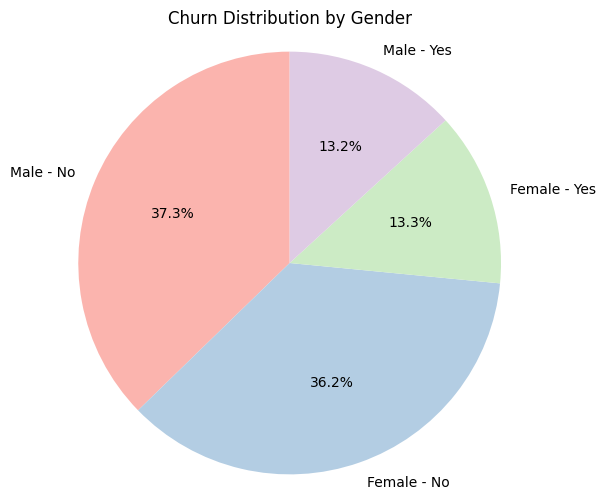

In [ ]:
# Count the gender-Churn combinations
counts = df[['gender', 'Churn']].value_counts()

# Convert to DataFrame for clarity
df_pie = counts.reset_index(name='count')

# Map 0/1 to Female/Male for gender
gender_map = {0: 'Female', 1: 'Male'}
churn_map = {0: 'No', 1: 'Yes'}

# Combined labels with readable text
labels = df_pie.apply(lambda row: f"{gender_map[row['gender']]} - {churn_map[row['Churn']]}", axis=1)

# Values to plot
sizes = df_pie['count']

# Plot
plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=plt.cm.Pastel1.colors)
plt.axis('equal')  # Perfect circle
plt.title("Churn Distribution by Gender")
plt.show()


We notice that the classes associated with Churn Yes - No are unbalanced in favor of the latter.
When defining the model's training and test datasets, we should take this into account so that the imbalance does not affect the model's accurate prediction (stratify parameter).


### Discrete continuous variables


In [ ]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

summary = pd.DataFrame({
    'min': df[num_cols].min(),
    'max': df[num_cols].max(),
    'mean': df[num_cols].mean(),
    'median': df[num_cols].median(),
    'std_dev': df[num_cols].std()
})

print(summary)


                  min      max         mean    median      std_dev
tenure           0.00    72.00    32.371149    29.000    24.559481
MonthlyCharges  18.25   118.75    64.761692    70.350    30.090047
TotalCharges    18.80  8684.80  2283.300441  1397.475  2266.771362


### MinMax Scaler for numeric variables

Since we have already transformed the categorical columns into binary values (0 and 1), we also apply the MinMaxScaler to numeric variables to bring them onto a scale between 0 and 1. This normalization is useful for models such as logistic regression, which benefit from features on similar scales to better understand the relationships between variables and avoid bias due to scale differences.

Before choosing this normalization technique, it is important to analyze the distribution of numeric columns to check for highly skewed distributions or significant outliers. In particular, the presence of extreme values can negatively affect the MinMaxScaler, shifting the normalized values and distorting the true representation of the data distribution.

### Features analysis

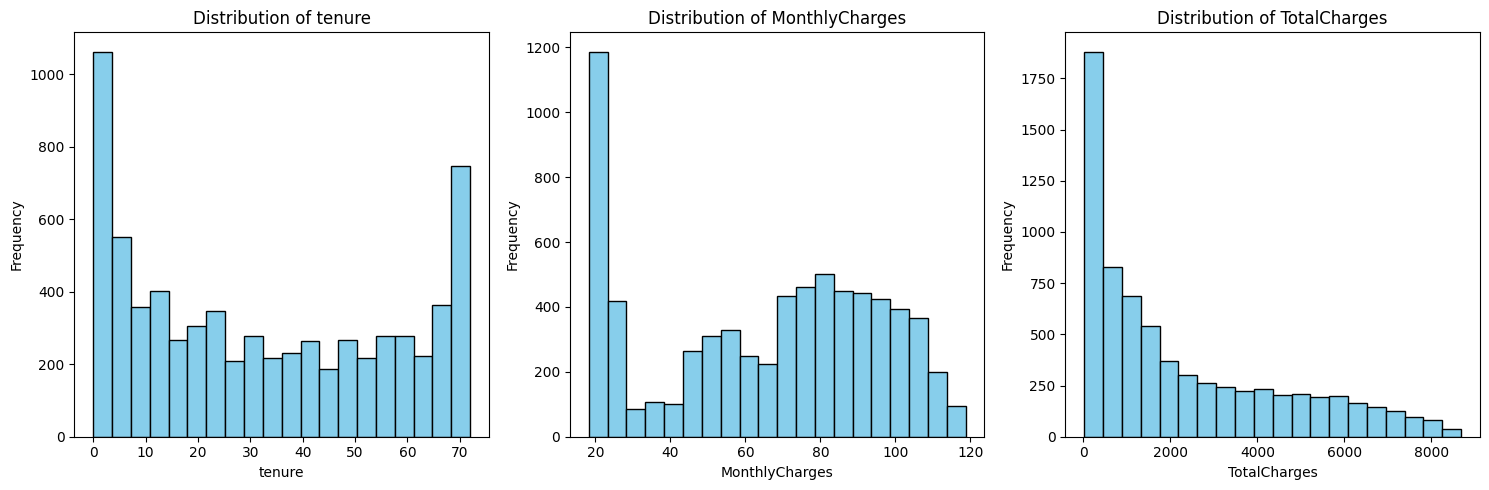

In [ ]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    plt.hist(df[col].dropna(), bins=20, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


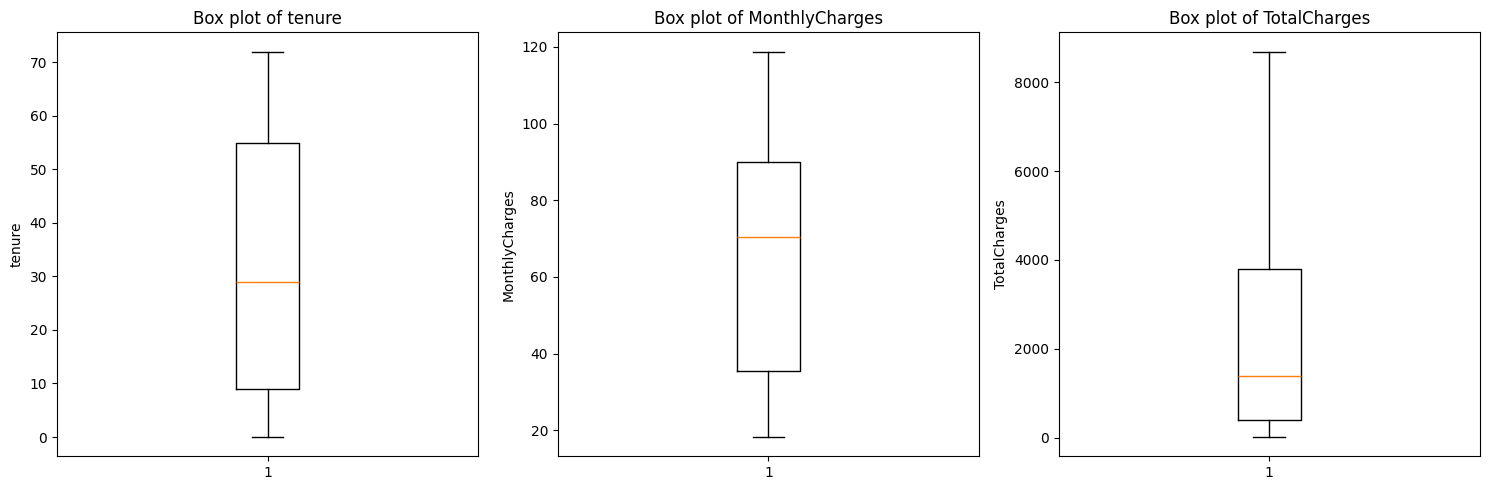

In [ ]:
plt.figure(figsize=(15, 5))

for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    plt.boxplot(df[col].dropna())
    plt.title(f'Box plot of {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


The distributions shown in the box plots do not reveal extreme outliers, as there are no points beyond the whiskers. However, the shapes of the distributions are highly skewed, particularly for TotalCharges, which has values concentrated at the lower end with a long right tail.

Analysis of distributions:

- **Tenure**: bimodal distribution, with many values near 0 and many near the maximum (around 70); fairly spread out but not strongly skewed.

- **MonthlyCharges**: slightly bimodal distribution, roughly uniform between 20 and 120, with a peak near the minimum.

- **TotalCharges**: heavily, positively skewed, with a long tail towards very high values.

To normalize the data, we can apply a **MinMaxScaler transformation** on Tenure, MonthlyCharges, and TotalCharges.

To avoid data leakage, it is crucial to split the DataFrame into train and test sets immediately. This way, the model cannot see statistical information from the test set during training. We then fit the MinMaxScaler only on the training data and subsequently transform both train and test using the same parameters.

### Multivariate analysis

### Pairplot

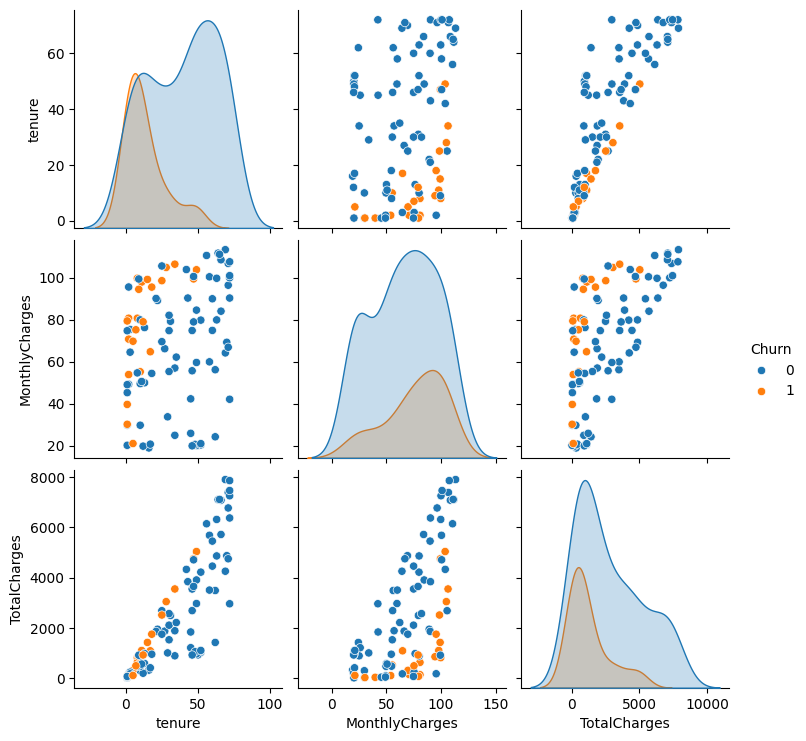

In [ ]:
# Take the first 100 rows
df2 = df.loc[0:99, ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

# Pairplot with hue for the binary target
sns.pairplot(df2, hue='Churn')


The pairplot shows the relationships between tenure, MonthlyCharges, and TotalCharges, highlighting the differences between customers who churned (orange) and those who did not (blue).

In the marketing context, **tenure** indicates the length of the relationship between the customer and the company, often expressed in months.

Univariate distributions (diagonal of the pairplot) with **association between numeric variables and churn yes/no**:

- **Tenure**: customers without churn (blue) are highly concentrated at high tenure values, while customers who churned (orange) tend to appear more at low values. Therefore, **we can define an association between long-term customers and low propensity to churn**.

- **MonthlyCharges**: similar distribution for churn and non-churn, but there is a slight higher density of churn customers at higher monthly charges. We can therefore consider that **higher monthly payments are slightly associated with higher churn propensity**.

- **TotalCharges**: separation is less clear compared to tenure, but **churners appear more concentrated in low total spend regions**.

Bivariate relationships (off-diagonal), i.e., **association between two features and churn**:

- **tenure vs TotalCharges**: almost perfectly linear relationship (expected, since TotalCharges ≈ tenure x MonthlyCharges), with **churn more frequent in customers with low tenure and low total spend**.

- **MonthlyCharges vs TotalCharges**: fan-shaped relationship, where **for the same MonthlyCharges, tenure explains the dispersion of churn positive yes (low tenure) and negative no (high tenure).**

- **tenure vs MonthlyCharges**: no strong linear relationship, but **churn appears more in the low tenure and high MonthlyCharges range**.

### Measure of collinearity between variables and correlation with target using Pearson (table) and Heatmap (plot)

In [ ]:
df.corr(numeric_only=True)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
gender,1.000000,-0.001874,-0.001808,0.010517,0.005106,-0.006488,-0.011754,-0.014569,0.000048,-0.008612,...,0.005374,0.006026,-0.010487,-0.003386,0.008026,-0.003695,-0.016024,0.001215,0.000752,0.013744
SeniorCitizen,-0.001874,1.000000,0.016479,-0.211185,0.016567,0.008576,0.156530,0.220173,0.102411,0.150889,...,0.034210,-0.182742,0.120176,0.138360,-0.046262,-0.117000,-0.016159,-0.024135,0.171718,-0.153477
Partner,-0.001808,0.016479,1.000000,0.452676,0.379697,0.017706,-0.014877,0.096848,0.319072,-0.150448,...,-0.117529,0.000615,0.117412,-0.280865,0.082783,0.248091,0.110706,0.082029,-0.083852,-0.095125
Dependents,0.010517,-0.211185,0.452676,1.000000,0.159712,-0.001762,-0.111377,-0.113890,0.064653,-0.164221,...,-0.078198,0.139812,-0.039741,-0.231720,0.068368,0.204613,0.052021,0.060267,-0.150642,0.059071
tenure,0.005106,0.016567,0.379697,0.159712,1.000000,0.008448,0.006152,0.247900,0.825880,-0.352229,...,-0.252220,-0.039062,0.286111,-0.645561,0.202570,0.558533,0.243510,0.233006,-0.208363,-0.233852
PhoneService,-0.006488,0.008576,0.017706,-0.001762,0.008448,1.000000,0.016505,0.247398,0.113008,0.011942,...,-0.112254,0.172209,-0.032959,-0.000742,-0.002791,0.003519,0.007556,-0.007721,0.003062,-0.003319
PaperlessBilling,-0.011754,0.156530,-0.014877,-0.111377,0.006152,0.016505,1.000000,0.352150,0.157830,0.191825,...,0.059488,-0.321013,0.211716,0.169096,-0.051391,-0.147889,-0.016332,-0.013589,0.208865,-0.205398
MonthlyCharges,-0.014569,0.220173,0.096848,-0.113890,0.247900,0.247398,0.352150,1.000000,0.651065,0.193356,...,0.018075,-0.763557,0.627429,0.060165,0.004904,-0.074681,0.042812,0.030550,0.271625,-0.377437
TotalCharges,0.000048,0.102411,0.319072,0.064653,0.825880,0.113008,0.157830,0.651065,1.000000,-0.199484,...,-0.202605,-0.374878,0.519867,-0.446776,0.170569,0.358036,0.186119,0.182663,-0.060436,-0.294708
Churn,-0.008612,0.150889,-0.150448,-0.164221,-0.352229,0.011942,0.191825,0.193356,-0.199484,1.000000,...,0.130845,-0.227890,0.061382,0.405103,-0.177820,-0.302253,-0.117937,-0.134302,0.301919,-0.091683


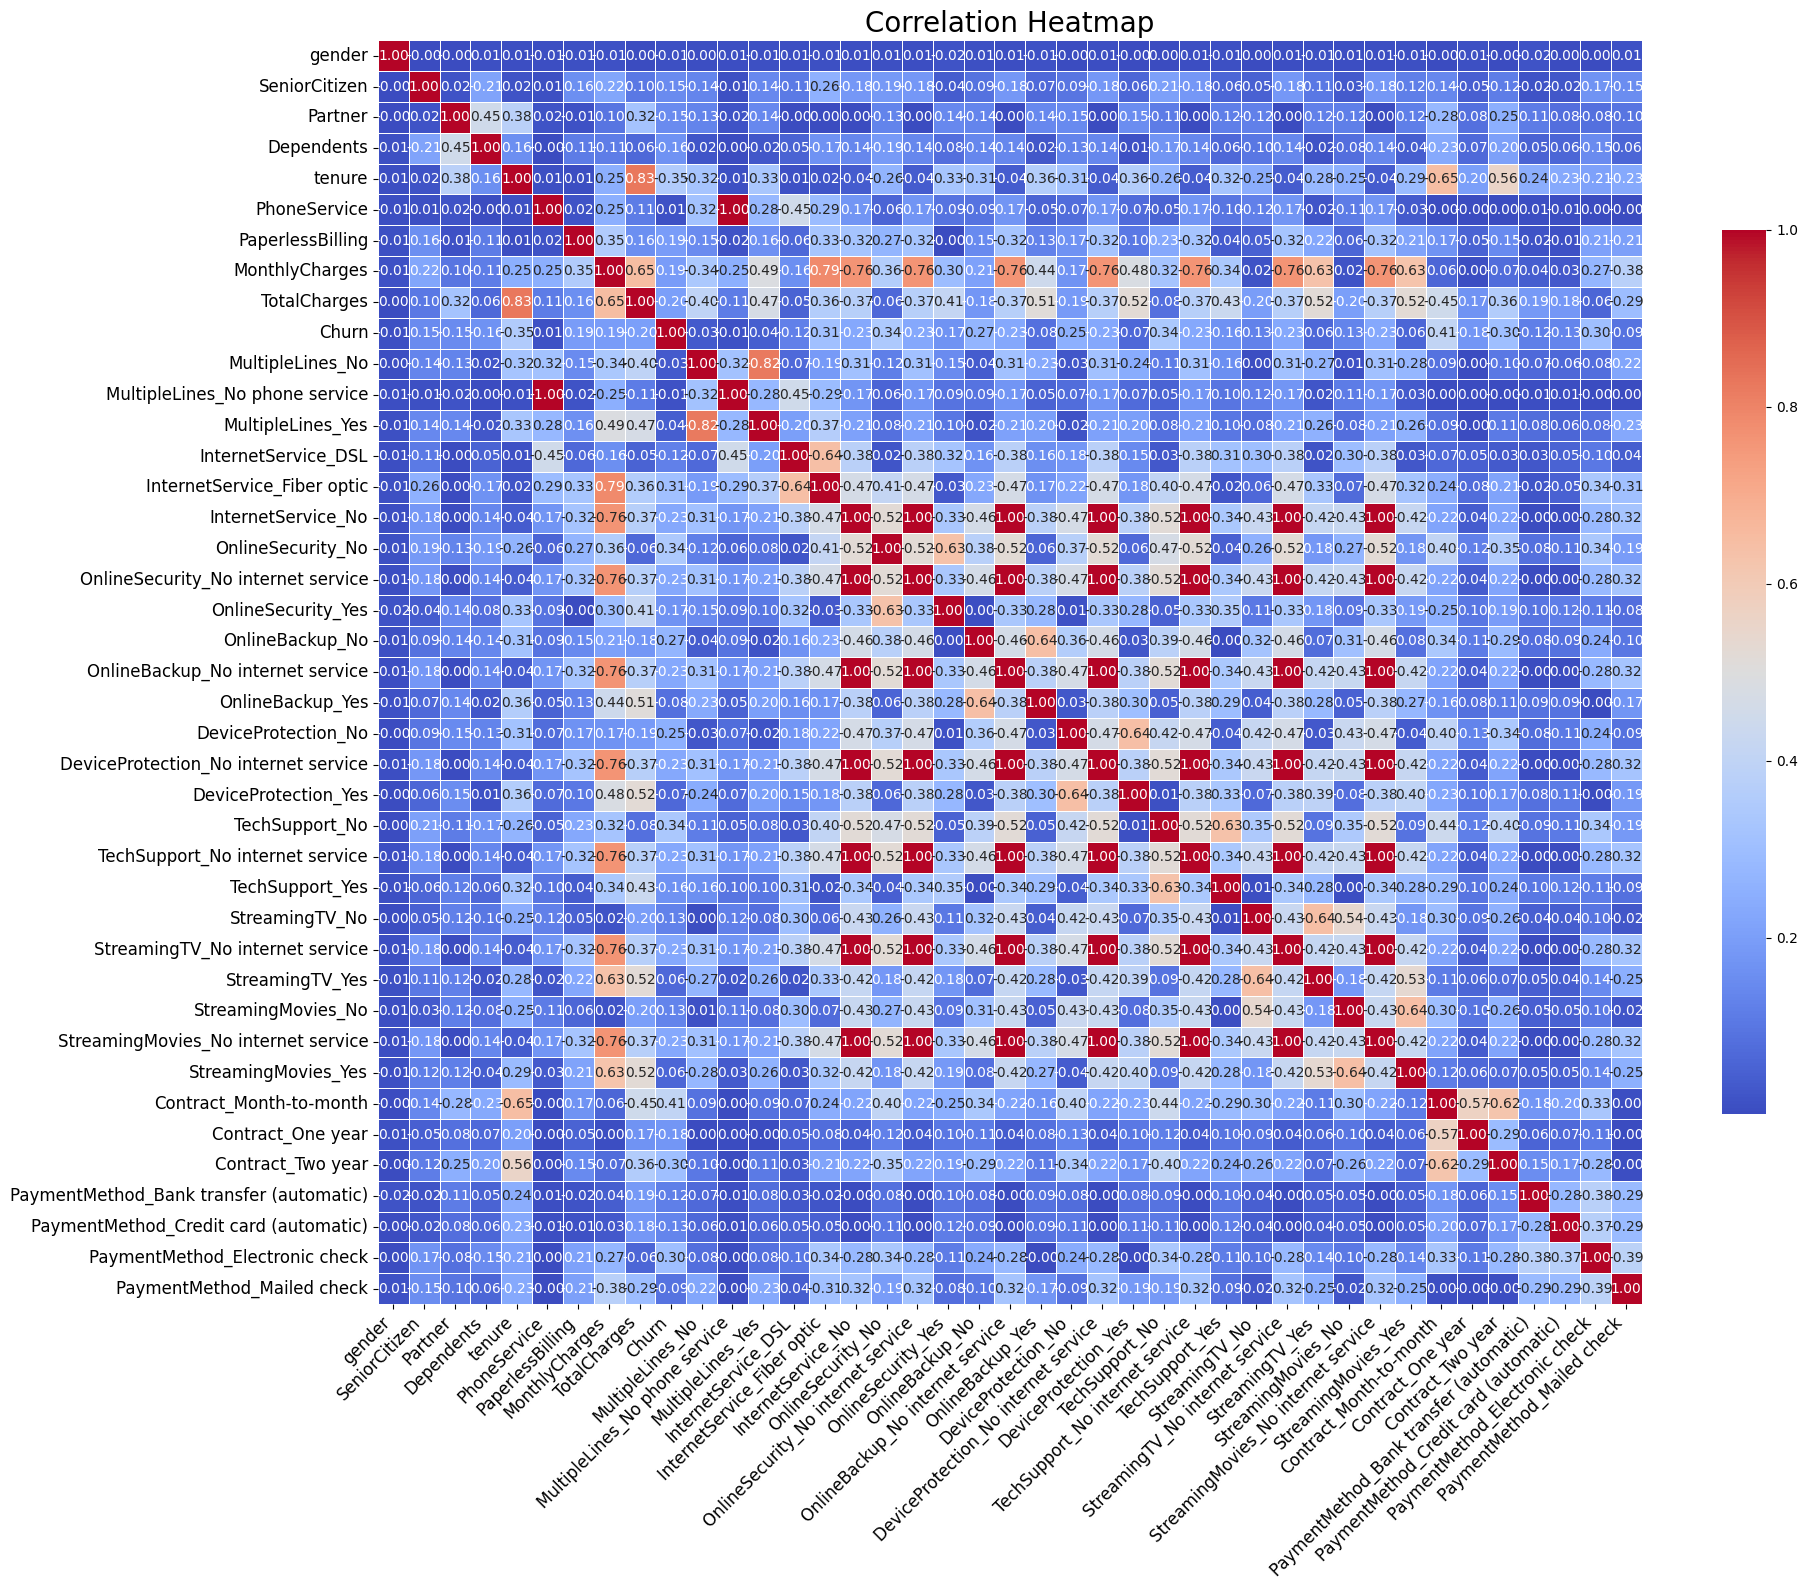

In [ ]:
# Calculate the correlation matrix
corr = df.corr(method='pearson', numeric_only=True)

plt.figure(figsize=(20, 16))

sns.heatmap(
    np.abs(corr),          # colors based on absolute correlation value
    annot=corr,            # annotations with original value (with sign)
    fmt=".2f",
    cmap='coolwarm',
    cbar_kws={"shrink": 0.7},
    linewidths=0.5,
    square=True,
    annot_kws={"size": 10}
)

plt.title("Correlation Heatmap", fontsize=20)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(rotation=0, fontsize=12)
plt.tight_layout()
plt.show()


In [ ]:
# Calculate correlations > 70% between features
threshold = 0.70

corr_pairs = (
    corr
    .abs()
    .unstack()
    .sort_values(ascending=False)
)

# Remove duplicates and self-correlations
corr_pairs = corr_pairs[
    (corr_pairs < 1) &
    (~corr_pairs.index.duplicated()) &
    (corr_pairs.index.get_level_values(0) != corr_pairs.index.get_level_values(1))
]

# Filter: > threshold and neither feature is Churn
high_corr_features = corr_pairs[
    (corr_pairs > threshold) &
    (~corr_pairs.index.get_level_values(0).isin(['Churn'])) &
    (~corr_pairs.index.get_level_values(1).isin(['Churn']))
]

# Display full list without truncation
pd.set_option('display.max_rows', None)

print("Feature pairs with correlation > 70% (excluding Churn):")
print(high_corr_features)


Feature pairs with correlation > 70% (excluding Churn):
tenure                                TotalCharges                            0.825880
TotalCharges                          tenure                                  0.825880
MultipleLines_Yes                     MultipleLines_No                        0.822853
MultipleLines_No                      MultipleLines_Yes                       0.822853
MonthlyCharges                        InternetService_Fiber optic             0.787066
InternetService_Fiber optic           MonthlyCharges                          0.787066
OnlineBackup_No internet service      MonthlyCharges                          0.763557
OnlineSecurity_No internet service    MonthlyCharges                          0.763557
MonthlyCharges                        OnlineSecurity_No internet service      0.763557
                                      OnlineBackup_No internet service        0.763557
                                      InternetService_No                  

In [ ]:
# Calculate correlation of all numeric columns with Churn
churn_corr = corr['Churn']

# All correlations with Churn sorted by absolute value
churn_corr_sorted = churn_corr.reindex(churn_corr.abs().sort_values(ascending=False).index)

print("\nAll correlations with Churn (sorted by absolute value):")
print(churn_corr_sorted)



All correlations with Churn (sorted by absolute value):
Churn                                      1.000000
Contract_Month-to-month                    0.405103
tenure                                    -0.352229
OnlineSecurity_No                          0.342637
TechSupport_No                             0.337281
InternetService_Fiber optic                0.308020
Contract_Two year                         -0.302253
PaymentMethod_Electronic check             0.301919
OnlineBackup_No                            0.268005
DeviceProtection_No                        0.252481
StreamingTV_No internet service           -0.227890
TechSupport_No internet service           -0.227890
StreamingMovies_No internet service       -0.227890
DeviceProtection_No internet service      -0.227890
OnlineBackup_No internet service          -0.227890
OnlineSecurity_No internet service        -0.227890
InternetService_No                        -0.227890
TotalCharges                              -0.199484
Monthly

Analyzing **collinearity between features** (a **negative** characteristic that generates redundant information) and **correlation between features and target** (a **positive** characteristic that enriches information), a problem emerges: **many features are strongly collinear**, as they derive from One Hot Encoding of the original variables.  

To **optimize** the dataset, we perform **Feature Selection** with a code that:

1. Identifies groups of dummies coming from OHE and groups them using the identical part of the name before the first “_”.
2. For each group with three or four dummy variables:
   - Compute the absolute correlation of each dummy with Churn.
   - Remove the dummy feature least correlated with Churn, keeping all the others in the group.
   - In case of a tie, remove the dummy most collinear with the other features.

In [ ]:
# Calculate correlation matrix
corr = df.corr(method='pearson', numeric_only=True)

# List of all columns except target
features = [col for col in df.columns if col != 'Churn']

# 1. Group dummy columns by prefix before "_"
dummy_groups = {}
for col in features:
    if "_" in col:
        prefix = col.split("_")[0]
        dummy_groups.setdefault(prefix, []).append(col)

# 2. Select columns to drop (one per group) and columns to keep (the others)
to_drop = []
to_keep = [col for col in features if "_" not in col]  # keep all columns without dummy group

for prefix, cols in dummy_groups.items():
    if len(cols) < 2:
        # group with a single dummy column, keep it
        to_keep.extend(cols)
        continue

    # Compute absolute correlation with Churn
    churn_corr = corr.loc[cols, 'Churn'].abs()
    min_corr = churn_corr.min()

    # Find candidates least correlated with Churn (to drop)
    worst_candidates = churn_corr[churn_corr == min_corr].index.tolist()

    if len(worst_candidates) == 1:
        drop_col = worst_candidates[0]
    else:
        # If tie, choose the one with highest average correlation with other features
        avg_corr_with_others = corr.loc[worst_candidates, features].abs().mean(axis=1)
        drop_col = avg_corr_with_others.idxmax()

    to_drop.append(drop_col)
    # Keep the other columns in the group
    to_keep.extend([c for c in cols if c != drop_col])

# 3. Output
print("Columns to KEEP (all except one per dummy group):")
print(to_keep)
print("\nColumns to DROP (one per dummy group):")
print(to_drop)

# 4. Create a new DataFrame without the columns to drop
df_reduced = df.drop(columns=to_drop)


Columns to KEEP (all except one per dummy group):
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'MultipleLines_No', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'TechSupport_No', 'TechSupport_No internet service', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'Contract_Month-to-month', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check']

Columns to DROP (one per dummy group):
['MultipleLines_No phone service', 'InternetService_DSL', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes

### Machine Learning

In this phase, we **analyze interpretability, predictive power, and sensitivity to data** of three models useful for binary classification, predicting Churn 0 - 1: **Logistic Regression**, **Random Forest** (an ensemble of decision trees), and **XGBoost - Extreme Gradient Boosting** (a boosting algorithm based on decision trees, where each new tree corrects the errors of the previous ones).



In [ ]:
# Remove the customerID column
df_model = df_reduced.drop(columns=['customerID'])

# Split
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

# Stratify to balance the classes (y = Churn is unbalanced)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaling only on the training set
scaler = MinMaxScaler()
X_train[['tenure', 'MonthlyCharges', 'TotalCharges']] = scaler.fit_transform(
    X_train[['tenure', 'MonthlyCharges', 'TotalCharges']]
)

# Transform on the test set
X_test[['tenure', 'MonthlyCharges', 'TotalCharges']] = scaler.transform(
    X_test[['tenure', 'MonthlyCharges', 'TotalCharges']]
)

# Display without index
print("X_train (first 5 rows):")
print(X_train.head().to_string(index=False))

print("\nX_test (first 5 rows):")
print(X_test.head().to_string(index=False))


X_train (first 5 rows):
 gender  SeniorCitizen  Partner  Dependents   tenure  PhoneService  PaperlessBilling  MonthlyCharges  TotalCharges  MultipleLines_No  MultipleLines_Yes  InternetService_Fiber optic  InternetService_No  OnlineSecurity_No  OnlineSecurity_No internet service  OnlineBackup_No  OnlineBackup_No internet service  DeviceProtection_No  DeviceProtection_No internet service  TechSupport_No  TechSupport_No internet service  StreamingTV_No  StreamingTV_No internet service  StreamingMovies_No  StreamingMovies_No internet service  Contract_Month-to-month  Contract_Two year  PaymentMethod_Bank transfer (automatic)  PaymentMethod_Credit card (automatic)  PaymentMethod_Electronic check
      1              0        0           0 0.486111             0                 0        0.306926      0.194185                 0                  0                            0                   0                  1                                   0                1                           

In [ ]:
# Initial shape check
print("Initial dimensions of X_train:", X_train.shape)
print("Initial dimensions of X_test:", X_test.shape)

# Check for NaN values
print("\nNaN values in X_train:")
print(X_train.isnull().sum()[X_train.isnull().sum() > 0])

print("\nNaN values in X_test:")
print(X_test.isnull().sum()[X_test.isnull().sum() > 0])

# Data types
print("\nData types in X_train:")
print(X_train.dtypes)

# Remove rows with NaN
X_train = X_train.dropna()
X_test = X_test.dropna()
y_train = y_train.loc[X_train.index]
y_test = y_test.loc[X_test.index]

# Check rows with NaN
print("Rows with at least one NaN in X_train:", X_train.isnull().any(axis=1).sum())
print("Rows with at least one NaN in X_test:", X_test.isnull().any(axis=1).sum())


Initial dimensions of X_train: (5634, 30)
Initial dimensions of X_test: (1409, 30)

NaN values in X_train:
TotalCharges    8
dtype: int64

NaN values in X_test:
TotalCharges    3
dtype: int64

Data types in X_train:
gender                                       int64
SeniorCitizen                                int64
Partner                                      int64
Dependents                                   int64
tenure                                     float64
PhoneService                                 int64
PaperlessBilling                             int64
MonthlyCharges                             float64
TotalCharges                               float64
MultipleLines_No                             int64
MultipleLines_Yes                            int64
InternetService_Fiber optic                  int64
InternetService_No                           int64
OnlineSecurity_No                            int64
OnlineSecurity_No internet service           int64
OnlineBackup_No    

### Logistic Regression

In [ ]:
# Initialize and train the model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Predictions
y_pred_prob = model.predict_proba(X_test)[:, 1]  # Probability of the positive class
y_pred = model.predict(X_test)  # Predicted labels

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.798719772403983
Confusion Matrix:
 [[917 115]
 [168 206]]
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.89      0.87      1032
           1       0.64      0.55      0.59       374

    accuracy                           0.80      1406
   macro avg       0.74      0.72      0.73      1406
weighted avg       0.79      0.80      0.79      1406



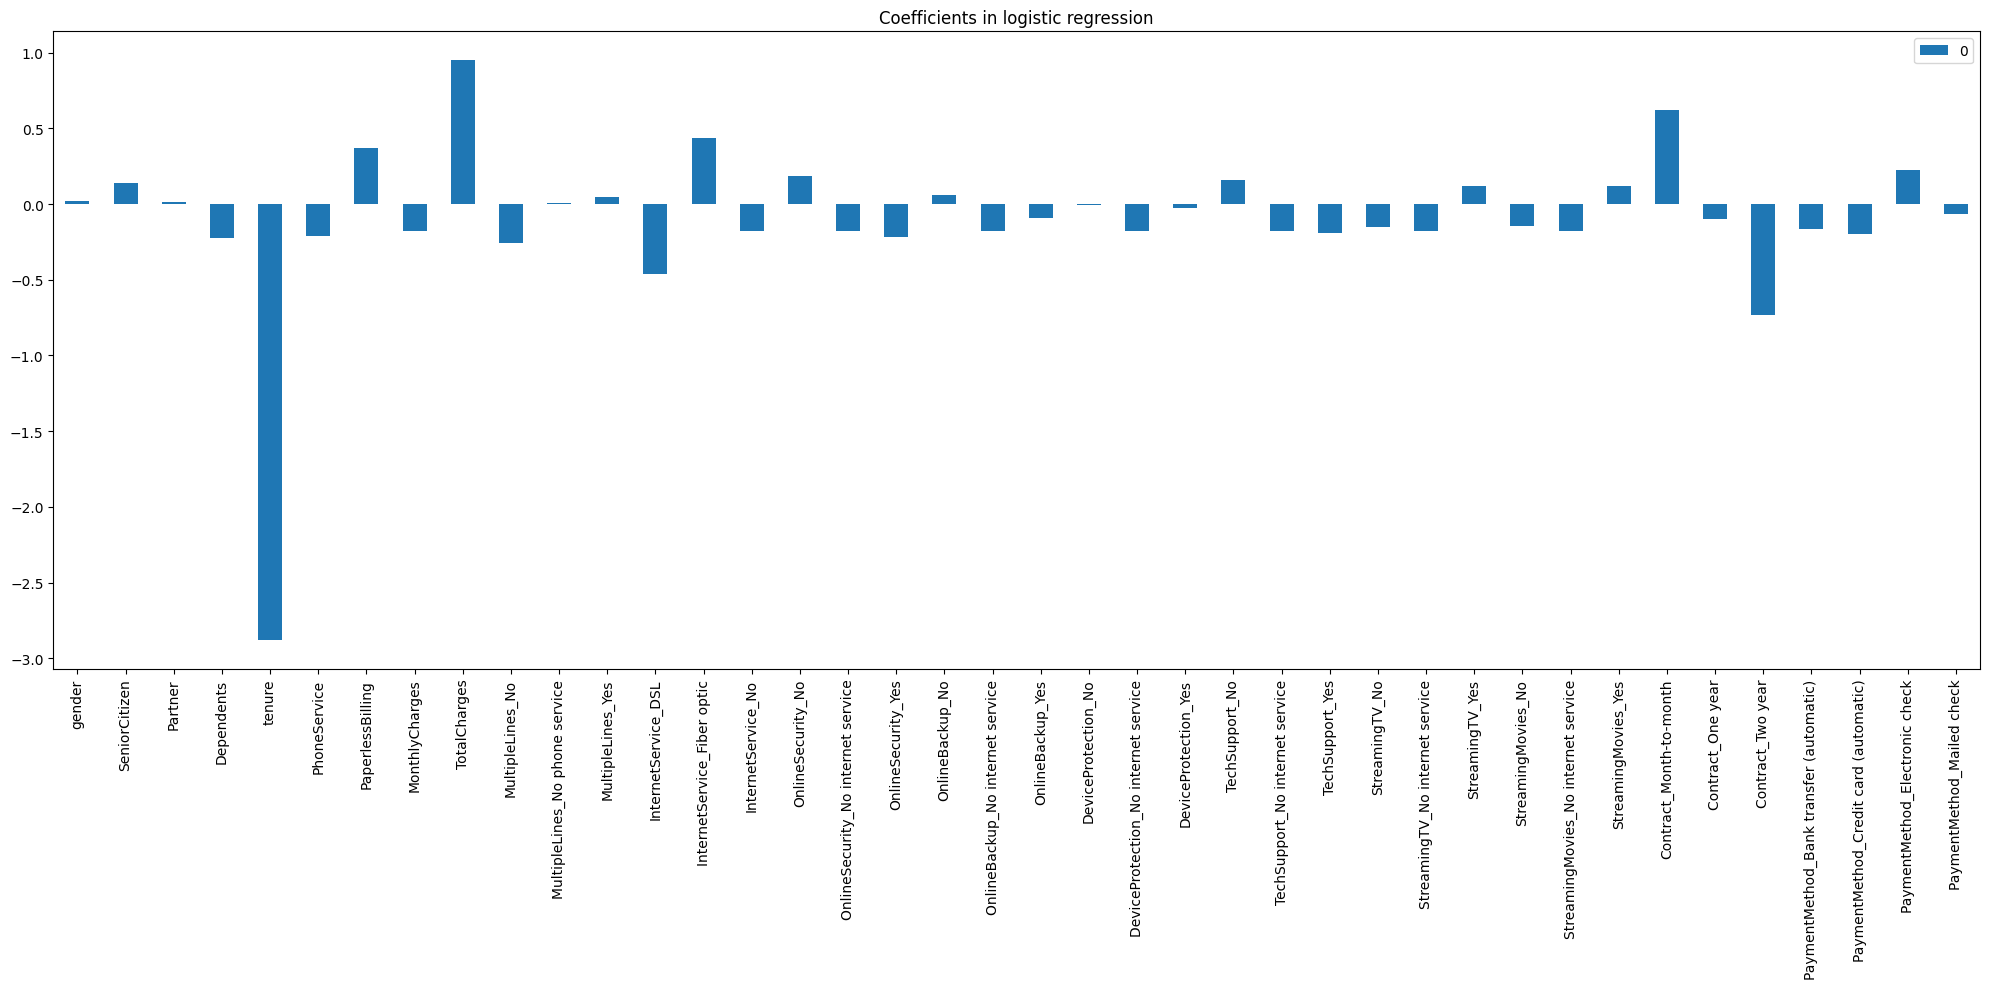

In [ ]:
df_coef = pd.DataFrame(model.coef_).transpose()
df_coef.index = X.columns

df_coef.plot(kind='bar', figsize=(20, 10))
plt.title('Coefficients in logistic regression')
plt.tight_layout()
plt.show()

### Logistic Regression Model Optimization - Hyperparameter Tuning

The **C parameter** controls the intensity of L2 regularization: small values impose strong regularization (**smaller coefficients, simpler model**), while large values reduce it, increasing flexibility but also the risk of **overfitting**.

To select the best C value, we use a **grid search**, a technique that scans a grid of C values and evaluates performance (e.g., accuracy) to identify the **optimal trade-off** between **bias** and **variance**.

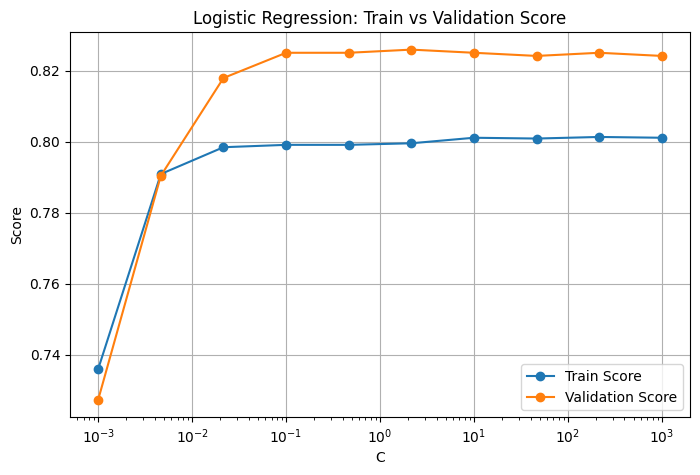

Logistic Regression (C=2.154434690031882) Accuracy: 0.7994310099573257
Confusion Matrix:
 [[916 116]
 [166 208]]
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.89      0.87      1032
           1       0.64      0.56      0.60       374

    accuracy                           0.80      1406
   macro avg       0.74      0.72      0.73      1406
weighted avg       0.79      0.80      0.79      1406



In [ ]:
def scan_logistic_reg_train_val(X, y, C_values=None):
    if C_values is None:
        C_values = np.logspace(-3, 3, 10)  # from 0.001 to 1000

    results = {
        'C': [],
        'train_score': [],
        'val_score': []
    }

    X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

    for C in C_values:
        model = LogisticRegression(C=C, max_iter=1000, random_state=42)
        model.fit(X_tr, y_tr)
        results['C'].append(C)
        results['train_score'].append(model.score(X_tr, y_tr))
        results['val_score'].append(model.score(X_val, y_val))

    return results

def plot_train_val_scores(results):
    import matplotlib.pyplot as plt
    plt.figure(figsize=(8,5))
    plt.semilogx(results['C'], results['train_score'], label='Train Score', marker='o')
    plt.semilogx(results['C'], results['val_score'], label='Validation Score', marker='o')
    plt.xlabel('C')
    plt.ylabel('Score')
    plt.title('Logistic Regression: Train vs Validation Score')
    plt.legend()
    plt.grid(True)
    plt.show()

# Run the scan
results = scan_logistic_reg_train_val(X_train, y_train)

# Plot the results
plot_train_val_scores(results)

# Find the best C (maximum validation score)
best_index = np.argmax(results['val_score'])
best_C = results['C'][best_index]

# Train the final model with the best C
final_model = LogisticRegression(C=best_C, max_iter=1000, random_state=42)
final_model.fit(X_train, y_train)
y_pred_final = final_model.predict(X_test)

# Evaluation
print(f"Logistic Regression (C={best_C}) Accuracy:", accuracy_score(y_test, y_pred_final))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_final))
print("Classification Report:\n", classification_report(y_test, y_pred_final))


### Comment on the "Train vs Validation Accuracy - Logistic Regression" plot

Both curves (**train and validation**) show an **increase in accuracy** as the parameter C increases. The gap between the two curves is small, which is a positive aspect: the model generalizes quite well and does not show overfitting.

The optimal value of **C** seems to be **chosen correctly**. In fact, at a certain point, **the curves stabilize**, suggesting that further increases in C do not lead to additional improvements and the **model expresses its maximum learning potential**.

### Random Forest

In [ ]:
# Random Forest Model
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# Predictions
y_pred_rf = rf.predict(X_test)
y_pred_rf_prob = rf.predict_proba(X_test)[:, 1]  # Positive class probability

# Evaluation
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))


Random Forest Accuracy: 0.7806955287437899
Confusion Matrix:
 [[912 123]
 [186 188]]
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.88      0.86      1035
           1       0.60      0.50      0.55       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



### Random Forest - Most important features in prediction


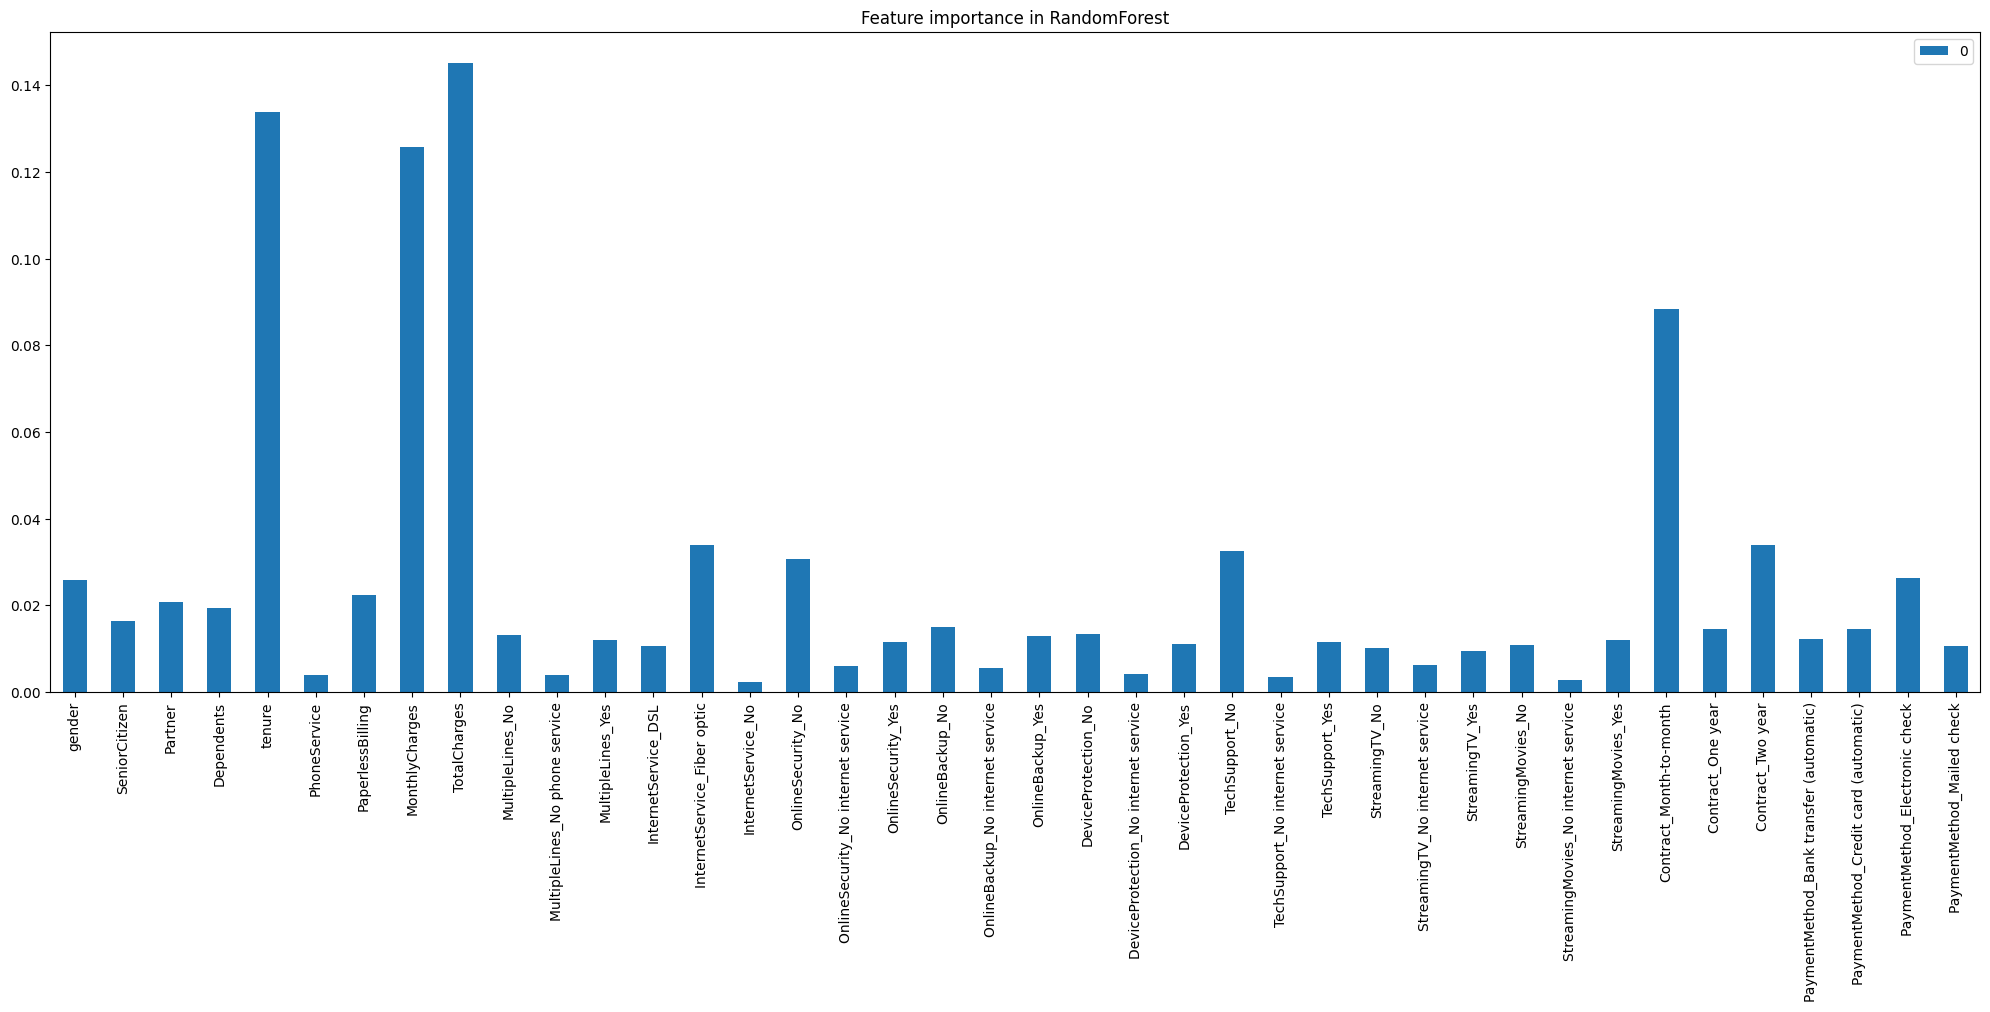

In [ ]:
df_coef_rf = pd.DataFrame(rf.feature_importances_)
df_coef_rf.index = X.columns

df_coef_rf.plot(kind='bar', figsize=(20, 10))
plt.tight_layout()
plt.title('Feature importance in RandomForest')
plt.show()

### Optimization of a Random Forest with Optuna

**Optuna** is a **hyperparameter optimization library** that explores the hyperparameter space using a Bayesian optimization algorithm and finds the best model hyperparameter configuration within a maximum number of trials.

Applying Optuna to a **RandomForestClassifier** optimizes hyperparameters such as:

* `n_estimators` (number of trees)
* `max_depth` (maximum depth)
* `min_samples_split` / `min_samples_leaf`
* `max_features`

In [ ]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', None])
    }

    clf = RandomForestClassifier(**params, random_state=42, n_jobs=-1)
    score = cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')
    return score.mean()

In [ ]:
# Silence Optuna loggers
#optuna.logging.set_verbosity(optuna.logging.CRITICAL)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

In [ ]:
best_params = study.best_params
print("Best hyperparameters found:", best_params)

best_rf = RandomForestClassifier(**best_params, random_state=42, n_jobs=-1)
best_rf.fit(X_train, y_train)

y_pred = best_rf.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, average='weighted')
test_recall = recall_score(y_test, y_pred, average='weighted')
test_f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Test set Accuracy: {test_acc:.3f}")
print(f"Test set Precision: {test_precision:.3f}")
print(f"Test set Recall: {test_recall:.3f}")
print(f"Test set F1-score: {test_f1:.3f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)


Best hyperparameters found: {'n_estimators': 229, 'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
Test set Accuracy: 0.803
Test set Precision: 0.793
Test set Recall: 0.803
Test set F1-score: 0.795
Confusion Matrix:
 [[935  97]
 [180 194]]


### XGBoost Classifier

In [ ]:
# XGBoost model
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)
xgb.fit(X_train, y_train)

# Predictions
y_pred_xgb = xgb.predict(X_test)

# Evaluation
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost Precision:", precision_score(y_test, y_pred_xgb))
print("XGBoost Recall:", recall_score(y_test, y_pred_xgb))
print("XGBoost F1 Score:", f1_score(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("Classification Report:\n", classification_report(y_test, y_pred_xgb))


XGBoost Accuracy: 0.7965860597439545
XGBoost Precision: 0.6401273885350318
XGBoost Recall: 0.5374331550802139
XGBoost F1 Score: 0.5843023255813954
Confusion Matrix:
 [[919 113]
 [173 201]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.89      0.87      1032
           1       0.64      0.54      0.58       374

    accuracy                           0.80      1406
   macro avg       0.74      0.71      0.72      1406
weighted avg       0.79      0.80      0.79      1406



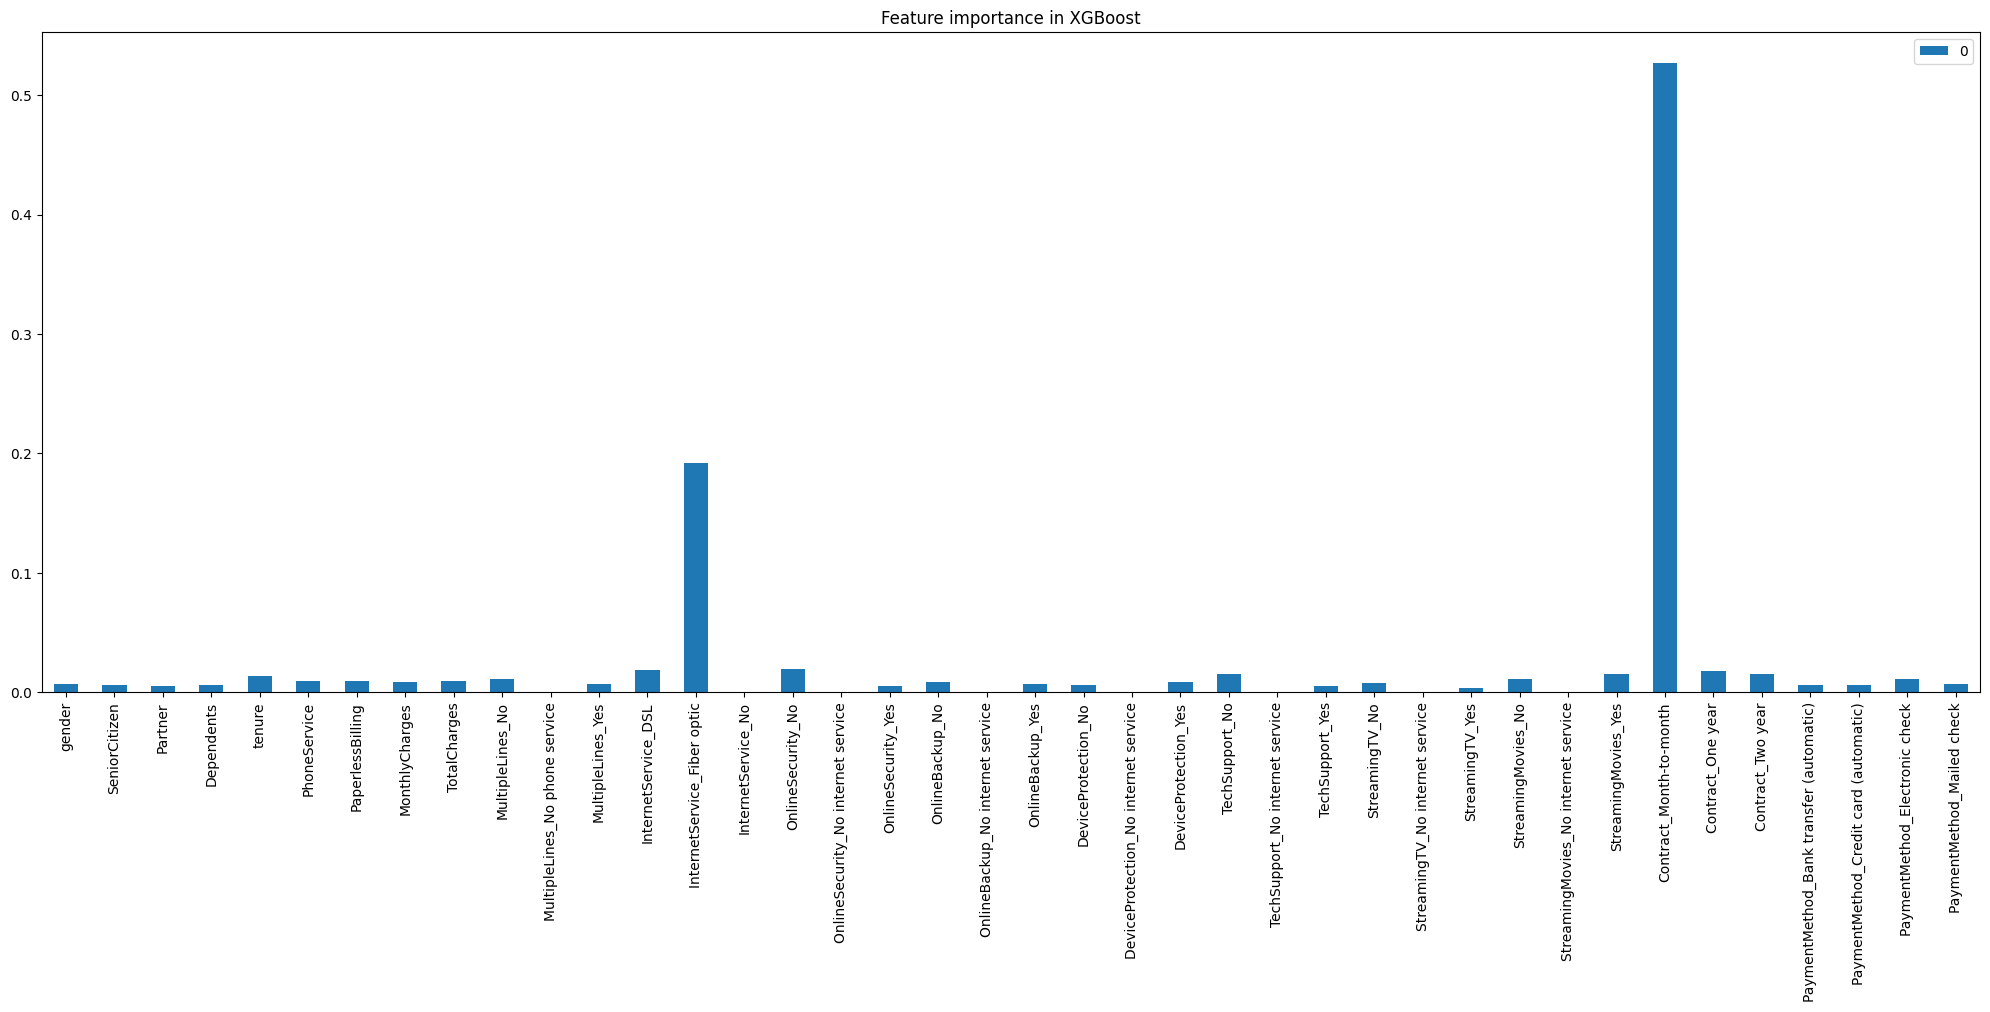

In [ ]:
df_coef_xgb = pd.DataFrame(xgb.feature_importances_)
df_coef_xgb.index = X.columns

df_coef_xgb.plot(kind='bar', figsize=(20, 10))
plt.tight_layout()
plt.title('Feature importance in XGBoost')
plt.show()

### XGBoost Classifier Optimization with Optuna


In [ ]:
# Silence Optuna loggers
optuna.logging.set_verbosity(optuna.logging.CRITICAL)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 300),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'eval_metric': 'logloss',
        'random_state': 42
    }

    model = XGBClassifier(**params)
    score = cross_val_score(model, X_train, y_train, cv=3, scoring='accuracy')
    return score.mean()

# Optimization with Optuna
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

# Best model
best_params = study.best_params
print("Best hyperparameters found:", best_params)

best_xgb = XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
best_xgb.fit(X_train, y_train)

y_pred_xgb = best_xgb.predict(X_test)

# Evaluation
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("XGBoost Precision:", precision_score(y_test, y_pred_xgb))
print("XGBoost Recall:", recall_score(y_test, y_pred_xgb))
print("XGBoost F1 Score:", f1_score(y_test, y_pred_xgb))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("Classification Report:\n", classification_report(y_test, y_pred_xgb))


Best hyperparameters found: {'n_estimators': 272, 'learning_rate': 0.06151086871873988, 'max_depth': 3, 'subsample': 0.8009021707134639, 'colsample_bytree': 0.5492518285270244}
XGBoost Accuracy: 0.8093883357041252
XGBoost Precision: 0.6827586206896552
XGBoost Recall: 0.5294117647058824
XGBoost F1 Score: 0.5963855421686747
Confusion Matrix:
 [[940  92]
 [176 198]]
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.91      0.88      1032
           1       0.68      0.53      0.60       374

    accuracy                           0.81      1406
   macro avg       0.76      0.72      0.74      1406
weighted avg       0.80      0.81      0.80      1406



**Model Considerations**

The **Random Forest** model with parameters optimized via **Optuna** proved to be the most performant in terms of Accuracy and key metrics:

- **Accuracy** - percentage of correct predictions overall: 81%
- **Precision** - ratio of predicted Churn 1 that are actually Churn 1: 80%
- **Recall** - ratio of true Churn 1 captured among all actual Churn 1: 81%
- **F1-score** - harmonic mean of precision and recall: 80%

The three most influential variables in predicting churn are **Tenure**, **MonthlyCharges**, and **TotalCharges**, which had already emerged as the most correlated with the **Churn target** during the preliminary exploratory data analysis (Pearson correlation and Heatmap).

The correlation is observed both **individually** and in combination with the most influential variable (**Tenure**) paired with the other two, producing significant additive effects on determining **Churn 0-1** (Pairplot graph).

### Churn Customer Profile - Part 1: Analysis of risk variables and their statistical relevance in overall Churn.

We consider the **profiles** associated with **Churn yes** predicted by the model, i.e., from the test set, **to evaluate their demographic characteristics, customer behavior, and consumption patterns**.

- For **binary variables**, we calculate to what extent each **variable class contributes** to determining **Churn 1**, i.e., the **percentage probability** of causing Churn 1 for each binary categorical variable class.

- For **discrete continuous variables**, we analyze the **mean value of the Churn 1 cluster** (**Tenure** = customer relationship duration, **MonthlyCharges** = monthly expenditure, **TotalCharges** = total expenditure since the beginning of the customer relationship).

### Most Influential Variables on Churn Prediction by the Model


Top 10 variables most important for Churn prediction:
                                Importance
TotalCharges                      0.168076
tenure                            0.145881
MonthlyCharges                    0.143799
Contract_Month-to-month           0.066304
TechSupport_No                    0.031366
PaymentMethod_Electronic check    0.028059
gender                            0.027713
InternetService_Fiber optic       0.027281
PaperlessBilling                  0.025284
OnlineSecurity_No                 0.025271


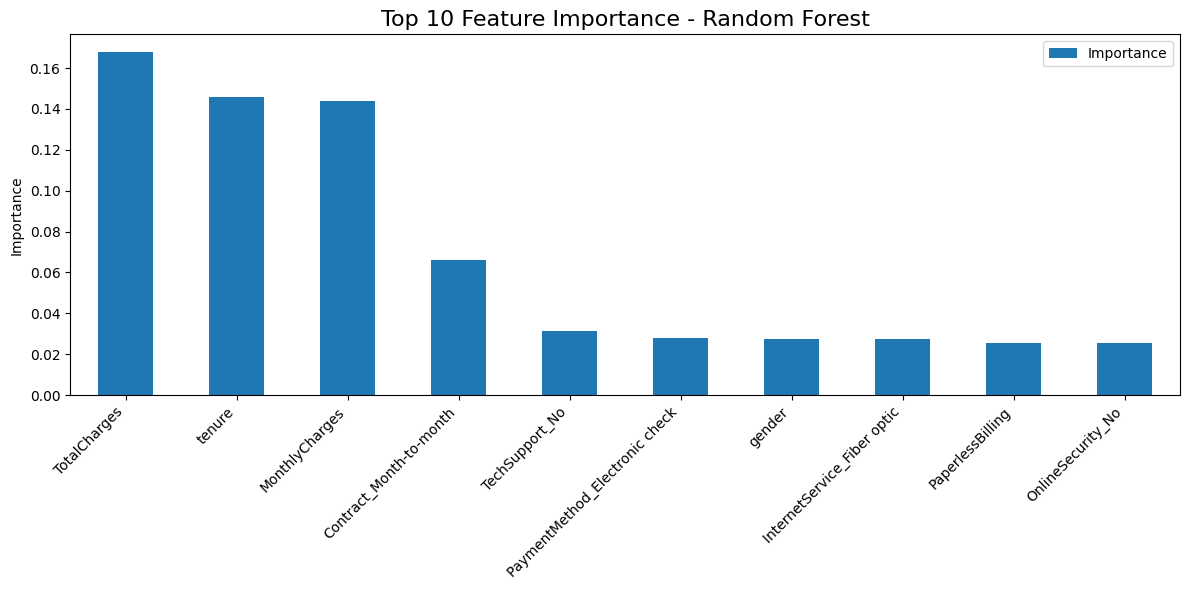

In [ ]:
# Create DataFrame with feature importance
df_coef_best_rf = pd.DataFrame({
    'Importance': rf.feature_importances_
}, index=X.columns)

# Sort in descending order
df_top10 = df_coef_best_rf.sort_values(by='Importance', ascending=False).head(10)

# Display the list
print("Top 10 variables most important for Churn prediction:")
print(df_top10)

# Plot the top 10
df_top10.plot(kind='bar', figsize=(12, 6), color='tab:blue')
plt.title('Top 10 Feature Importance - Random Forest', fontsize=16)
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


The crucial correlation with Churn of the three variables **TotalCharges**, **Tenure**, and **MonthlyCharges** is confirmed, as observed in the preliminary exploratory data analysis (EDA).


### Churn Customer Profile

We analyze the **average probability with which each variable contributes to predicting Churn=1**. This allows us to outline the **profile of at-risk customers** across the entire dataset and to identify **targeted offer adjustments and marketing strategies for customer retention**.

In [ ]:
# Prediction of probability and class on the test set
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]  # probability of class 1

# Add predictions and probability to the test dataframe
test_with_pred = X_test.copy()
test_with_pred['Predicted_Churn'] = y_pred
test_with_pred['Prob_Churn_1'] = y_prob
test_with_pred['True_Churn'] = y_test.values  # if y_test is a Series, use .values to align

# Group by predicted cluster (0 or 1)
grouped = test_with_pred.groupby('Predicted_Churn')

# List of numerical variables to average
numerical_vars = ['tenure', 'MonthlyCharges', 'TotalCharges']

# List of binary variables (all except numerical and target)
binary_vars = [col for col in X_test.columns if col not in numerical_vars]

# Compute average probability and mean values for each group
summary = pd.DataFrame()

# For binary variables: mean = probability of 1
summary_binary = grouped[binary_vars].mean()

# For numerical variables: simple mean
summary_num = grouped[numerical_vars].mean()

# Add the mean of the true target (actual Churn) to understand the difference
summary_target = grouped['True_Churn'].mean()

# Combine everything into a single dataframe
summary = pd.concat([summary_binary, summary_num, summary_target.rename('True_Churn_Mean')], axis=1)

print("Average profile per predicted churn cluster (0 and 1):")
print(summary)


Average profile per predicted churn cluster (0 and 1):
                   gender  SeniorCitizen   Partner  Dependents  PhoneService  \
Predicted_Churn                                                                
0                0.508520       0.124664  0.539910    0.352466      0.905830   
1                0.525773       0.285223  0.237113    0.120275      0.938144   

                 PaperlessBilling  MultipleLines_No  \
Predicted_Churn                                       
0                        0.549776          0.504933   
1                        0.776632          0.477663   

                 MultipleLines_No phone service  MultipleLines_Yes  \
Predicted_Churn                                                      
0                                      0.094170           0.400897   
1                                      0.061856           0.460481   

                 InternetService_DSL  ...  Contract_One year  \
Predicted_Churn                       ...                 

In [ ]:
# Transformation to invert MinMaxScaler for Tenure, MonthlyCharges, and TotalCharges from the values calculated in summary

# Summary with original min and max values
summary_stats = {
    "tenure": {"min": 0.00, "max": 72.00},
    "MonthlyCharges": {"min": 18.25, "max": 118.75},
    "TotalCharges": {"min": 18.80, "max": 8684.80}
}

# Normalized mean values from the model (summary for churn=1 cluster)
scaled_means = {
    "tenure": 0.132752,
    "MonthlyCharges": 0.588750,
    "TotalCharges": 0.094595
}

# Function to invert MinMaxScaler
def inverse_minmax(scaled_val, var):
    min_val = summary_stats[var]["min"]
    max_val = summary_stats[var]["max"]
    return scaled_val * (max_val - min_val) + min_val

# Calculate and print original values
for var, val in scaled_means.items():
    orig_val = inverse_minmax(val, var)
    print(f"{var}: {orig_val:.2f}")


tenure: 9.56
MonthlyCharges: 77.42
TotalCharges: 838.56


### Churn Customer Profile - Average Value of Continuous Discrete Variables for Churn 1

### Summary Statistics of Variables (calculated in initial EDA)

| Variable           |   min  |   max   |     mean     |  median  |  std_dev   |
|--------------------|--------|---------|--------------|----------|------------|
| **tenure**         |  0.00  |  72.00  |  32.371149   |  29.000  |  24.559481 |
| **MonthlyCharges** | 18.25  | 118.75  |  64.761692   |  70.350  |  30.090047 |
| **TotalCharges**   | 18.80  | 8684.80 | 2283.300441  | 1397.475 | 2266.771362 |

---

The summary values for the three variables before normalization with MinMax were:

- Tenure: min = 0, max = 72  
- MonthlyCharges: min = 18.25, max = 118.75  
- TotalCharges: min = 18.80, max = 8684.80  

---

### Normalized Mean Values (churn=1 profile)

- Tenure = 0.132752  
- MonthlyCharges = 0.588750  
- TotalCharges = 0.094595  

---

### Conversion from MinMax to original values

- tenure_orig = 0.132752 * (72 - 0) + 0  
  = 0.132752 * 72  
  ≈ **9.56** months

- mc_orig = 0.588750 * (118.75 - 18.25) + 18.25  
  = 0.588750 * 100.5 + 18.25  
  ≈ **77.4** €

- tc_orig = 0.094595 * (8684.80 - 18.80) + 18.80  
  = 0.094595 * 8666 + 18.80  
  ≈ **839.4** €

---

### Average high-risk customer profile (churn=1 cluster) in real values

**Tenure** = **9.6** months

- Compared to the mean value of 32 months (almost 3 years) and maximum 72 months, this customer relationship is very short.

**MonthlyCharges** = **77.4** €  

- Compared to the mean of 65 € (3-year average) and maximum 119 €, associated with only 9 months of relationship, the economic burden is relatively high.

**TotalCharges** = **839** €

- Consistent with a short 9-month tenure and high charges.


Binary variables ordered by maximum churn propensity:

- Contract_Month-to-month: 1.00
- PhoneService: 0.94
- TechSupport_No: 0.92
- OnlineSecurity_No: 0.91
- InternetService_Fiber optic: 0.83
- OnlineBackup_No: 0.81
- DeviceProtection_No: 0.79
- PaperlessBilling: 0.76
- PaymentMethod_Electronic check: 0.67
- StreamingTV_No: 0.66
- StreamingMovies_No: 0.63
- Partner: 0.54
- MultipleLines_No: 0.52
- gender: 0.52
- MultipleLines_Yes: 0.42
- InternetService_DSL: 0.39
- StreamingMovies_Yes: 0.38
- StreamingTV_Yes: 0.37
- DeviceProtection_Yes: 0.37
- OnlineBackup_Yes: 0.35
- Dependents: 0.35
- TechSupport_Yes: 0.33
- OnlineSecurity_Yes: 0.33
- Contract_Two year: 0.30
- InternetService_No: 0.28
- OnlineSecurity_No internet service: 0.28
- OnlineBackup_No internet service: 0.28
- DeviceProtection_No internet service: 0.28
- TechSupport_No internet service: 0.28
- StreamingTV_No internet service: 0.28
- StreamingMovies_No internet service: 0.28
- Contract_One year: 0.27
- SeniorCitizen: 0.26
-

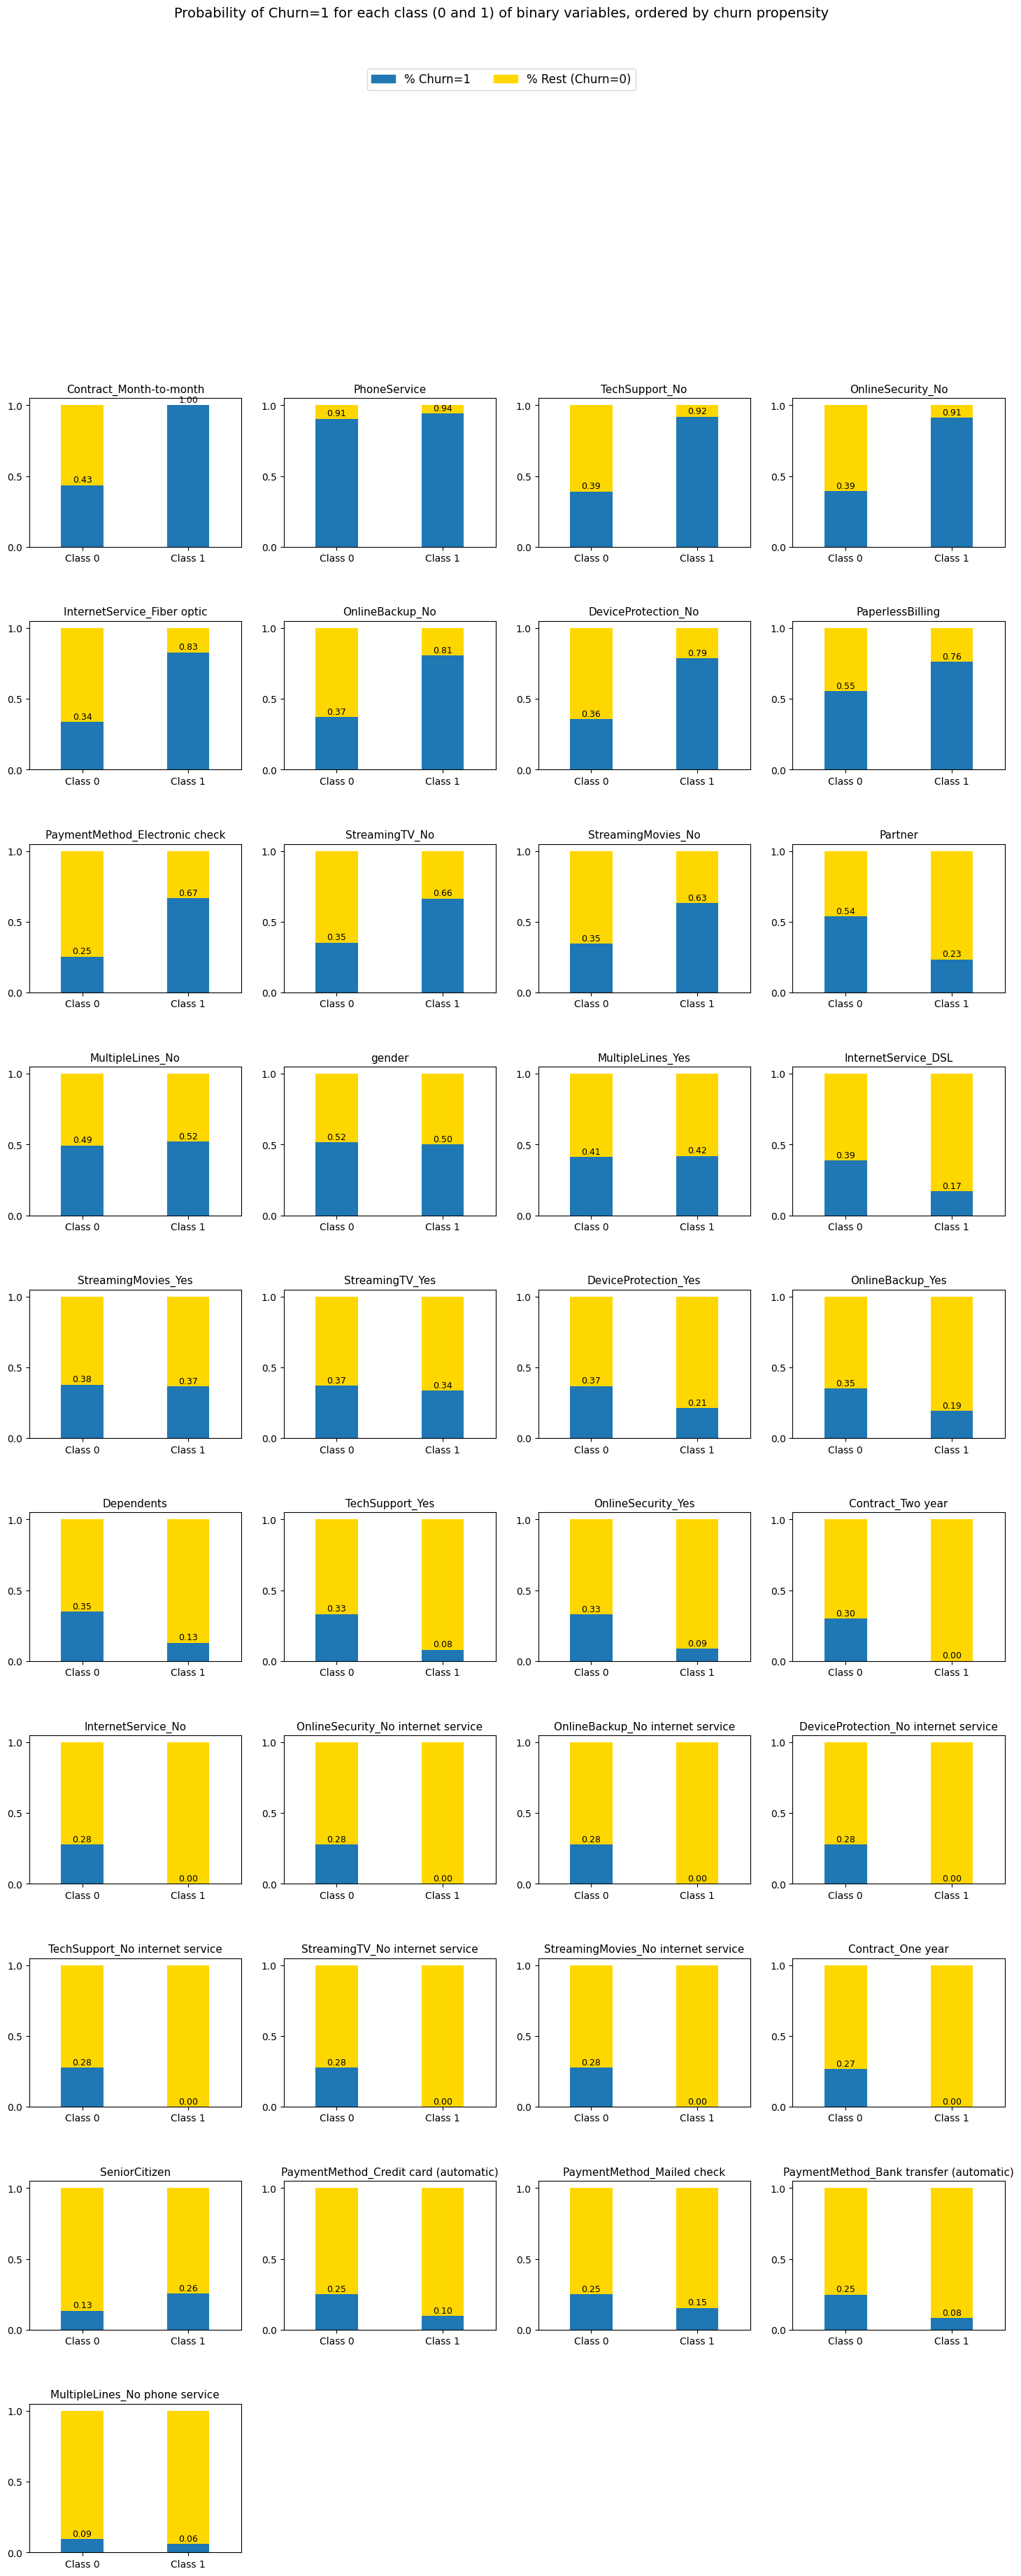

In [ ]:
# Select all binary variables (excluding numerical and target)
numerical_vars = ['tenure', 'MonthlyCharges', 'TotalCharges']
binary_vars = [col for col in summary.columns if col not in numerical_vars and col != 'True_Churn_Mean']

# Calculate churn propensity = max(prob churn=1 across classes 0 and 1)
propensity = {}
for var in binary_vars:
    val_0 = summary.loc[0, var]
    val_1 = summary.loc[1, var]
    propensity[var] = max(val_0, val_1)

# Sort variables by descending propensity
ordered_binary_vars = sorted(propensity, key=propensity.get, reverse=True)

# Print the list of variables sorted
print("Binary variables ordered by maximum churn propensity:\n")
for var in ordered_binary_vars:
    print(f"- {var}: {propensity[var]:.2f}")

# Number of variables to visualize
n_vars = len(ordered_binary_vars)
n_cols = 4
n_rows = int(np.ceil(n_vars / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

# Colors
colors = {
    'Churn=1': 'tab:blue',
    'Rest': 'gold'
}

for i, var in enumerate(ordered_binary_vars):
    ax = axes[i]

    # Values for class 0 and 1
    val_0 = summary.loc[0, var]
    val_1 = summary.loc[1, var]

    # Side-by-side vertical bars
    ax.bar(x=0, height=val_0, color=colors['Churn=1'], width=0.4)
    ax.bar(x=0, height=1 - val_0, bottom=val_0, color=colors['Rest'], width=0.4)

    ax.bar(x=1, height=val_1, color=colors['Churn=1'], width=0.4)
    ax.bar(x=1, height=1 - val_1, bottom=val_1, color=colors['Rest'], width=0.4)

    # Labels
    ax.text(0, val_0 + 0.02, f"{val_0:.2f}", ha='center', fontsize=9)
    ax.text(1, val_1 + 0.02, f"{val_1:.2f}", ha='center', fontsize=9)

    # Title with propensity
    ax.set_title(f"{var}", fontsize=11)
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, 1.05)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Class 0', 'Class 1'])
    ax.set_yticks([0, 0.5, 1])

# Remove any empty subplots
for j in range(n_vars, len(axes)):
    fig.delaxes(axes[j])

# Global title
fig.suptitle(
    "Probability of Churn=1 for each class (0 and 1) of binary variables, ordered by churn propensity",
    fontsize=14,
    y=1.02
)

# Global legend above subplots
fig.legend(
    [plt.Rectangle((0, 0), 1, 1, color=colors['Churn=1']),
     plt.Rectangle((0, 0), 1, 1, color=colors['Rest'])],
    ['% Churn=1', '% Rest (Churn=0)'],
    loc='upper center',
    ncol=2,
    fontsize=12,
    bbox_to_anchor=(0.5, 1.0)
)

# Increase vertical space between subplot rows
plt.subplots_adjust(hspace=0.5, top=0.88)

plt.show()


### Most Influential Variables for Positive Churn:

1. **Contract_Month-to-month**: all customers with a month-to-month contract (not a one-year 'Contract_One year' or two-year 'Contract_Two year') have churned.
2. **OnlineSecurity_No**: almost all (91%) customers not using Online Security service (the variable is a dummy, so No security online = 1) have churned.
3. **TechSupport_No**: nearly all (92%) customers who never used Tech Support service (dummy variable, so No support = 1) have churned.
4. **PhoneService**: churned customers are equally divided between those who have (94%) and those who do not have (91%) Phone Service.
5. **InternetService_Fiber optic**: 83% of customers with Fiber Optic Internet service (instead of DSL) have churned.
6. **OnlineBackup_No**: 81% of customers not using **Online Backup** (dummy variable, No = 1) have churned.
7. **PaperlessBilling**: 74% of customers using digital billing have churned.
8. **DeviceProtection_No**: more than three-quarters (79%) of customers not using Device Protection (dummy variable, No = 1) have churned.
9. **PaymentMethod_Electronic check**: 67% of customers who paid via electronic check (instead of automatic bank transfer or credit card or postal check) have churned.

For other variables, the probability of generating Churn=1 is around 50%, evenly distributed between Churn=1 and Churn=0, with no clear predominance; the influence of each variable in determining Churn=1 progressively decreases.

### Churn Customer Profile:

- **Type of contract**: the Churn profile consists entirely of customers with **month-to-month contracts** (the other two options are one-year or two-year contracts).

- **Services NOT purchased**: all customers who **do not use Online Security** and 81% of those not using **Online Backup**. Also, all customers who never used **Tech Support**. Finally, 79% of those without **Device Protection** have churned. Two deductions:
  1. **Digital and internet-related protection services** appear to influence customer retention more than services related to **Entertainment**, such as TV or Movie Streaming.
  2. Using **Tech Support** is typically an important moment for **customer loyalty to the brand**.

- **Services purchased**: 83% of customers with **Fiber Optic Internet** (instead of DSL) have churned, showing two possible tendencies: **sensitivity to faster Internet solutions** and **lower brand loyalty**, making it easier to leave due to purchasing the cheaper service.

- **Payment method**: more then 2 out of 3 customers using **simple payment methods** (not automatic bank transfer or credit card) decide to churn. Again, a **weaker relationship** with the service seems to encourage leaving.


### Profilo Cliente Churn - Parte 2: Analisi dei cluster ottenuti dalla segmentazione della clientela tramite **KMeans** e della rilevanza statistica del rischio di churn su scale crescenti.  

Il modello **KMeans** è comunemente utilizzato per individuare **gruppi omogenei di clienti**, caratterizzati da **comportamenti e bisogni simili** all’interno di un dataset (es. *“giovani con contratti mensili e alto churn”* vs *“clienti anziani con contratti annuali e basso churn”*). La segmentazione si basa su **proprietà statistiche condivise** (es. medie, varianze) che consentono di evidenziare cluster distinti per abitudini di consumo e comportamento.  

In questo modo emergono **pattern non lineari** che i modelli predittivi tradizionali non riescono a catturare, offrendo una visione più approfondita delle dinamiche di abbandono.  

**Obiettivo: segmentare il rischio di churn e sviluppare strategie di retention marketing mirate per ciascun cluster.**

In [ ]:
df_reduced.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No,...,StreamingTV_No,StreamingTV_No internet service,StreamingMovies_No,StreamingMovies_No internet service,Contract_Month-to-month,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,Churn
0,1,0,0,0,0.486111,0,0,0.306926,0.194185,0,...,0,0,0,0,1,0,0,0,1,0
1,1,0,1,1,0.208333,1,0,0.565022,0.130707,1,...,1,0,1,0,1,0,0,0,0,0
2,1,0,1,1,0.180556,0,0,0.220727,0.065948,0,...,1,0,1,0,0,1,0,0,0,0
3,0,0,1,0,0.361111,1,1,0.549078,0.217731,1,...,0,0,0,0,0,1,0,1,0,0
4,1,0,1,1,0.013889,1,0,0.260588,0.002966,1,...,1,0,1,0,1,0,0,0,1,0


In [ ]:
# PCA
n_components = 5
pca = PCA(n_components=n_components)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Print explained variance
print(f"Explained variance by the {n_components} PCA components:")
for i, var in enumerate(pca.explained_variance_ratio_):
    print(f"  - Component {i+1}: {var:.4f}")

# KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_train_pca)

# Predict clusters
train_clusters = kmeans.predict(X_train_pca)
test_clusters = kmeans.predict(X_test_pca)

# Add clusters to original dataframes
X_train_clusters = X_train.copy()
X_train_clusters['Cluster'] = train_clusters

X_test_clusters = X_test.copy()
X_test_clusters['Cluster'] = test_clusters

# Print cluster distribution
print("\nCluster distribution in train set:")
print(X_train_clusters['Cluster'].value_counts())

print("\nCluster distribution in test set:")
print(X_test_clusters['Cluster'].value_counts())


Explained variance by the 5 PCA components:
  - Component 1: 0.2595
  - Component 2: 0.1448
  - Component 3: 0.0889
  - Component 4: 0.0509
  - Component 5: 0.0417

Cluster distribution in train set:
Cluster
1    2503
2    1913
0    1210
Name: count, dtype: int64

Cluster distribution in test set:
Cluster
1    635
2    461
0    310
Name: count, dtype: int64


The K-Means model identified:  

- **3 clusters (0, 1, and 2)**, reporting the number of clients in each (around 7,000 in total, corresponding to the number of rows in the dataset).  
- **Total variance explained by PCA**: 0.2595 + 0.1448 + 0.0889 + 0.0509 + 0.0417 = 0.5858. This means the first 5 PCA components explain roughly **60%** of the variability in the original data (the rest is in the remaining components). This allows a good balance between model simplicity, to avoid overfitting, and capturing the most important patterns in the data for cluster segmentation.  
- **Cluster distribution similar between train and test**: indicating that the clustering model is not overly biased toward one dataset over the other.

### Verification of Clusters via Plot and Hypothesis Testing

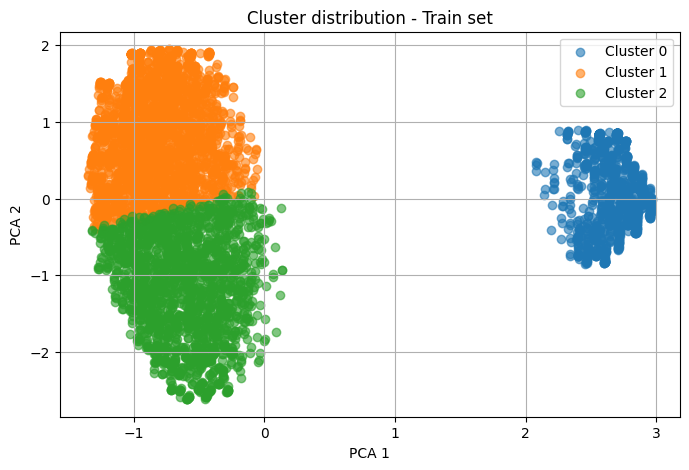

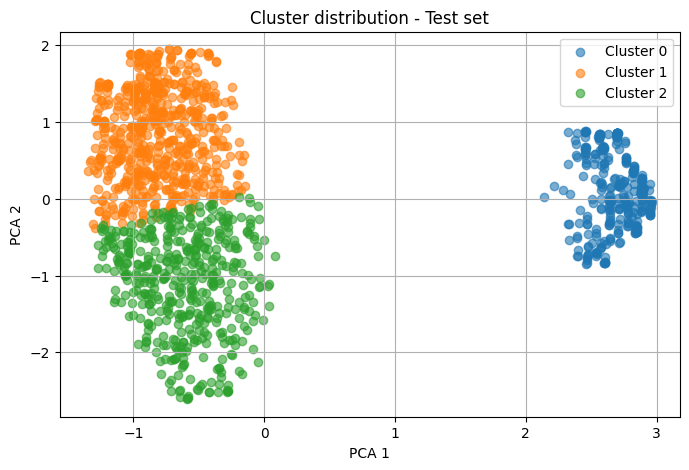

In [ ]:
# Plot for the train set
plt.figure(figsize=(8, 5))
for cluster_id in range(3):
    idx = train_clusters == cluster_id
    plt.scatter(X_train_pca[idx, 0], X_train_pca[idx, 1],
                label=f'Cluster {cluster_id}', alpha=0.6)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Cluster distribution - Train set')
plt.legend()
plt.grid(True)
plt.show()

# Plot for the test set
plt.figure(figsize=(8, 5))
for cluster_id in range(3):
    idx = test_clusters == cluster_id
    plt.scatter(X_test_pca[idx, 0], X_test_pca[idx, 1],
                label=f'Cluster {cluster_id}', alpha=0.6)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('Cluster distribution - Test set')
plt.legend()
plt.grid(True)
plt.show()


### Hypothesis Testing for Cluster Validation

Once the **customer segments** are identified, hypothesis tests are employed to validate the segmentation results and ensure that the **differences** between segments are **statistically significant** (Hair et al., 2018).

**T-tests, ANOVA, or chi-square tests** can be used to **compare means or proportions between variables**.

If the null hypothesis of equality of means or proportions is rejected, we can have confidence in the segmentation results.

### 1. ANOVA for continuous variables (tenure, MonthlyCharges, TotalCharges)


In [ ]:
# ANOVA test for each continuous variable
for var in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    group_0 = X_train_clusters[X_train_clusters['Cluster'] == 0][var]
    group_1 = X_train_clusters[X_train_clusters['Cluster'] == 1][var]
    group_2 = X_train_clusters[X_train_clusters['Cluster'] == 2][var]

    f_stat, p_value = f_oneway(group_0, group_1, group_2)

    print(f"\nANOVA on '{var}' across clusters:")
    print(f"F-statistic: {f_stat:.4f}, p-value: {p_value:.4f}")
    if p_value < 0.05:
        print("→ Significant differences between clusters (p < 0.05)")
    else:
        print("→ No significant differences between clusters (p ≥ 0.05)")



ANOVA on 'tenure' across clusters:
F-statistic: 1833.3708, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

ANOVA on 'MonthlyCharges' across clusters:
F-statistic: 5181.4658, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

ANOVA on 'TotalCharges' across clusters:
F-statistic: 3695.7727, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)


**Interpretation**

The results of the ANOVA test show that the continuous variables tenure, MonthlyCharges, and TotalCharges exhibit **statistically significant differences between clusters** (p-value < 0.05).

This means that the groups identified by KMeans are clearly distinguishable with respect to these variables, confirming that the segmentation is statistically valid and not random.


### 2. Chi-Square Test for Binary Variables (0-1)

In [ ]:
# List of binary variables
binary_vars = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'PaperlessBilling', 'MultipleLines_No', 'MultipleLines_No phone service',
    'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic',
    'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service',
    'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service',
    'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service',
    'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service',
    'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service',
    'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service',
    'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
    'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)',
    'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check',
    'PaymentMethod_Mailed check'
]

# Chi-square test for each binary variable
for var in binary_vars:
    contingency = pd.crosstab(X_train_clusters['Cluster'], X_train_clusters[var])
    chi2, p, dof, expected = chi2_contingency(contingency)

    print(f"\nChi-square test on '{var}' across clusters:")
    print(f"Chi2 statistic: {chi2:.4f}, p-value: {p:.4f}")
    if p < 0.05:
        print("→ Significant differences between clusters (p < 0.05)")
    else:
        print("→ No significant differences between clusters (p ≥ 0.05)")



Chi-square test on 'gender' across clusters:
Chi2 statistic: 3.2810, p-value: 0.1939
→ No significant differences between clusters (p ≥ 0.05)

Chi-square test on 'SeniorCitizen' across clusters:
Chi2 statistic: 213.2141, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

Chi-square test on 'Partner' across clusters:
Chi2 statistic: 522.4411, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

Chi-square test on 'Dependents' across clusters:
Chi2 statistic: 298.3129, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

Chi-square test on 'PhoneService' across clusters:
Chi2 statistic: 170.9523, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

Chi-square test on 'PaperlessBilling' across clusters:
Chi2 statistic: 583.0758, p-value: 0.0000
→ Significant differences between clusters (p < 0.05)

Chi-square test on 'MultipleLines_No' across clusters:
Chi2 statistic: 824.8173, p-value: 0.0000
→ Significant differe

### Interpretation:

The results of the chi-square test show that all binary variables exhibit **statistically significant differences across clusters** (p-value < 0.05), confirming that these variables also contribute to distinguishing the groups.

Understandably, the only exception is the variable 'gender', which has a p-value = 0.1939, indicating no significant difference between clusters.

The most discriminative binary variables include:
SeniorCitizen, Partner, Dependents, PhoneService, PaperlessBilling, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaymentMethod.

These variables are strongly characteristic of the cluster profiles and help better understand behavioral differences and offering choices among the groups.


### Customer Segmentation and Average Cluster Profile


### Churn Distribution Within Each Cluster


In [ ]:
# Use the dataframe already created with clusters
X_test_with_cluster = X_test_clusters.copy()

# Add target columns
X_test_with_cluster['True_Churn'] = y_test.values
X_test_with_cluster['Predicted_Churn'] = best_rf.predict(X_test)

# List of existing clusters
clusters = X_test_with_cluster['Cluster'].unique()

# Loop over clusters to analyze churn
for cluster_id in clusters:
    cluster_data = X_test_with_cluster[X_test_with_cluster['Cluster'] == cluster_id]

    churn_distribution = cluster_data['True_Churn'].value_counts(normalize=True)

    print(f"\n=== Churn Distribution in Cluster {cluster_id} ===")
    print(churn_distribution)



=== Churn Distribution in Cluster 2 ===
True_Churn
0    0.848156
1    0.151844
Name: proportion, dtype: float64

=== Churn Distribution in Cluster 1 ===
True_Churn
0    0.56063
1    0.43937
Name: proportion, dtype: float64

=== Churn Distribution in Cluster 0 ===
True_Churn
0    0.919355
1    0.080645
Name: proportion, dtype: float64


### Considerations

* **Customer distribution by Cluster (test_set)**:
  * 1    635
  * 2    461
  * 0    310

* **Cluster 0** (45.2%)

  * Only 8% of customers are at risk of churn (Churn=1), while 92% remain active.
  * This cluster therefore represents a **relatively stable group of customers**, with low risk of leaving.

* **Cluster 1** (32.8%)

  * 44% of customers are at risk of churn, almost equal to 56% who intend to stay.
  * This is a **high-risk cluster**, with a roughly 50-50 proportion of customers who could churn.

* **Cluster 2** (22.0%)

  * Only 15% of customers are at risk of churn, while 85% are expected to remain active.
  * This is a second cluster with **low churn risk, but slightly higher than Cluster 0**.

**General Conclusion:**
The three identified clusters show **different propensities to churn**:

* Cluster 1 has the **highest risk**, useful for targeted retention strategies.
* Clusters 0 and 2 have a **relatively low risk** and are more stable. For these groups, a **tailored retention strategy** can be applied.

**Summary:**

This detailed analysis on **cluster risk exposure** allows for **integration with the previous analysis** on **high-risk variables** and related **offer strengthening strategies**. Specifically, enriching the **customer dataset (Customer ID) with increasing risk levels** enables the definition of targeted actions, **prioritizing retention interventions** based on cluster risk.